
# Full GD-1 stream-membership pipeline (with CMD terms for background + stream)

This notebook runs the complete GD-1 stream-membership modeling pipeline end
to end:

1. **Background model** (`phi1, phi2, pm1, pm2, rv`, plus the new
   phi1-conditioned CMD normalizing-flow term
   fit standalone on `bkg_data`
2. **Stream model** (same coordinates, no CMD term -- CMD flow modeling is
   currently scoped to the background only), fit standalone on `stream_data`
3. **Background + stream mixture** model, fit jointly on `run_data`
4. **Full mixture model**, adding the spatial "offtrack" component

Because `ComponentMixtureModel` requires every component in a mixture to
share the same set of coordinates (see
`stream_membership.model.ComponentMixtureModel.__post_init__`), and the CMD
flow term is currently only implemented for the background component (not
stream/offtrack), the CMD flow is included in the **standalone** background
fit (Stage 1) but *not* in the Stage 3/4 joint mixtures, which use a
CMD-flow-free `bkg_model_mm` instead. Extending the CMD term to stream/
offtrack (so it could be included in the joint fit too) is future work,
consistent with the agreed "background model only" scope for this pass.

It mirrors the structure of `scripts/run_full_gd1_model.py` and
`notebooks/Pipeline-GD-1/5-AutoNormal_SVI.ipynb` (the most recent, up-to-date
pipeline notebook), but:

- Adds the pretrained CMD flow term to the background model via
  `initialize_stream.make_bkg_model_component(..., cmd_flow=..., cmd_norm_stats=...)`
  (see `scripts/cmd_flow_density.py` / `scripts/pretrain_bkg_cmd_flow.py`).
- Adds the fixed isochrone CMD term to the stream model via
  `initialize_stream.make_stream_model_component(..., stream_isochrone=...)`
  (see `scripts/generate_stream_isochrone.py` and
  `stream_membership.distributions.IsochroneCMD`). **Note:**
  `generate_stream_isochrone.py` needs one-time network access (to fetch MIST
  isochrone grid data) that may not be available in every environment -- see
  that script's docstring. If the cached
  `data/stream_isochrone_gaia.json` file isn't found, this notebook prints a
  warning and falls back to no stream CMD term (`stream_isochrone=None`), so
  it still runs end to end.
- Is self-contained: it does **not** `import *` from `run_full_gd1_model.py`
  (which unconditionally imports `cats` at module level), so it can be
  *structurally* run even in environments where `cats` (and its `ugali` /
  `healpy` dependencies) aren't installed.
- Uses the **current** `initialize_stream.make_stream_model_component` API,
  which requires `rv_min` / `rv_max` (added after `run_full_gd1_model.py` /
  older pipeline notebooks were last updated).


In [1]:

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np

import matplotlib.pyplot as plt
try:
    import cmasher as cmr
    CMAP = cmr.sunburst_r
    RESID_CMAP = cmr.fusion
except ImportError:
    CMAP = "viridis"
    RESID_CMAP = "RdBu_r"

from numpyro.infer.autoguide import AutoNormal

from stream_membership.plot import plot_data_projections
from stream_membership.model import ComponentMixtureModel

import astropy.table as at
import astropy.units as u

import pickle
from pathlib import Path
import sys

import traceback


In [2]:

# Locate the gd1-dr3 repo root so this notebook works both from a checkout at
# the hardcoded path used elsewhere in this repo (your machine) and from a
# differently-located clone / sandbox mount (e.g. this notebook's own parent
# directory).
_CANDIDATE_ROOTS = [
    Path("/Users/Tavangar/Work/gd1-dr3"),
    Path.cwd().parent,
    Path.cwd(),
]
ROOT_DIR = next((p for p in _CANDIDATE_ROOTS if (p / "data").exists() and (p / "scripts").exists()), _CANDIDATE_ROOTS[0])
DATA_DIR = ROOT_DIR / "data"
SCRIPTS_DIR = ROOT_DIR / "scripts"

sys.path.append(str(SCRIPTS_DIR))

import initialize_stream as init_stream
import pretrain_bkg_cmd_flow as cmd_flow_pretrain
import plot_stream_cmd
from cmd_flow_density import CalibratedFlowDensity
from svi_helpers import *
from initialization_helpers import fit_truncated_mixture_fixed_loc, fit_truncated_mixture

from cats.pawprint.pawprint import Pawprint
from cats.CMD import Isochrone
from cats.inputs import stream_inputs as inputs
from cats.proper_motions import ProperMotionSelection, rough_pm_poly

print(f"ROOT_DIR = {ROOT_DIR}")

ROOT_DIR = /Users/Tavangar/Work/gd1-dr3


## Pipeline configuration

In [3]:

STREAM_NAME = "GD-1"
PHI1_LIM = [-80, 20]

# Matches scripts/run_full_gd1_model.py's CLI defaults.
NUM_STEPS = dict(bkg=1_000, stream=5_000, bkg_stream=5_000, full=5_000)
PROXY_MAX_N = None
BKG_KNOT_SPACINGS = jnp.array([10, 5, 20, 20, 20])       # phi1, phi2, pm1, pm2, rv
STREAM_KNOT_SPACINGS = jnp.array([5, 10, 10, 10, 10])  # phi1, phi2, pm1, pm2, rv
N_MIXTURE = 2  # number of mixture components in the background pm1/pm2/rv models

OFFTRACK_DX = jnp.array([4, 1.5])  # [phi1, phi2] spacing (degrees)
OFFTRACK_OPTS = dict(
    lattice="diamond",
    fixed_scales=True,
    sigma_frac=1.0,
    weight_prior="dirichlet",
    logit_scale=2.0,
)

# Cache fitted SVI results here, keyed by knot spacing (see each stage below),
# so rerunning the notebook picks up existing fits instead of refitting from
# scratch. Smoke-test runs are cached in a separate subdirectory so they can
# never collide with (or clutter) real production results.
SVI_RESULTS_DIR = ROOT_DIR / "svi_results"
SVI_RESULTS_DIR = SVI_RESULTS_DIR / "flow_test"
SVI_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"NUM_STEPS = {NUM_STEPS}")
print(f"SVI_RESULTS_DIR = {SVI_RESULTS_DIR}")


NUM_STEPS = {'bkg': 1000, 'stream': 5000, 'bkg_stream': 5000, 'full': 5000}
SVI_RESULTS_DIR = /Users/Tavangar/Work/gd1-dr3/svi_results/flow_test


## Loading Data + Flow + Isochrone

The flow modeling `p(g, r | phi1)` for the background is
pretrained separately (see `scripts/pretrain_bkg_cmd_flow.py`) rather than
fit jointly with the rest of the mixture model -- same approach as the
`stream_mapper` PyTorch/zuko reference implementation.

Unlike the background CMD term (a fitted, phi1-conditioned normalizing
flow), the stream's CMD term (`IsochroneCMD`) uses a *fixed* isochrone
track -- old age, metal-poor, matching the population parameters already
used for GD-1's existing PS1-band isochrone pre-selection cut
(`cats.inputs.stream_inputs["GD-1"]`), generated directly in Gaia bands so
it lines up with `CMD_COORD = ("g", "r")` with no
photometric-system color transformation. See
`scripts/generate_stream_isochrone.py` for how the track is generated (a
one-time step requiring network access to fetch MIST grid data -- run it on
a machine with normal internet access, then copy the resulting
`data/stream_isochrone_gaia.json` here) and
`stream_membership.distributions.IsochroneCMD` for how the track is turned
into a probability density.

In [4]:
post_cats_path = DATA_DIR / "for_svi_w_isochrone_cut.pkl"

run_data,run_data_err,bkg_data,bkg_data_err,stream_data,stream_data_err,iso_obj,pawprint = create_svi_datasets(filename=post_cats_path)
coord_bounds, plot_grids = get_coord_bounds(run_data, pawprint)
phi1_lim = coord_bounds["phi1"]

CMD_FLOW_PREFIX = DATA_DIR / "flow_w_isochrone_cut/grid/bkg_cmd_flow_L8_W50_D2"
cmd_flow, cmd_norm_stats = load_CMD_flow(CMD_FLOW_PREFIX)

STREAM_ISOCHRONE_PATH = DATA_DIR / "stream_isochrone_gaia.json"
stream_isochrone = load_stream_isochrone(STREAM_ISOCHRONE_PATH)

Loaded cached CATS-processed data from /Users/Tavangar/Work/gd1-dr3/data/for_svi_w_isochrone_cut.pkl
run_data: 192495 rows, bkg_data: 157058 rows, stream_data: 2006 rows
Loaded pretrained CMD flow from /Users/Tavangar/Work/gd1-dr3/data/flow_w_isochrone_cut/grid/bkg_cmd_flow_L8_W50_D2.eqx
Loaded stream isochrone CMD track from /Users/Tavangar/Work/gd1-dr3/data/stream_isochrone_gaia.json


## Create All Models

In [5]:
bkg_model = init_stream.make_bkg_model_component(
    coords=['phi2', 'pm1', 'pm2', 'radial_velocity'],
    knot_spacings=BKG_KNOT_SPACINGS, n_mixture=N_MIXTURE,
    coord_bounds=coord_bounds, data=bkg_data, stream_data=stream_data,
    cmd_flow=cmd_flow, cmd_norm_stats=cmd_norm_stats,
)

rv_min = jnp.min(init_stream._coord_x(stream_data, "radial_velocity"))
rv_max = jnp.max(init_stream._coord_x(stream_data, "radial_velocity"))

selection_function = init_stream.make_mag_limit_selection_function(run_data)

stream_model = init_stream.make_stream_model_component(
    knot_spacings=STREAM_KNOT_SPACINGS, coord_bounds=coord_bounds, data=stream_data,
    rv_min=rv_min, rv_max=rv_max, stream_isochrone=stream_isochrone,
    selection_function=selection_function,   # luminosity_function="kroupa" is the default
)


#####################################################################
## MIXTURE WITHOUT OFFTRACK COMPONENT, FOR INITIALIZATION PURPOSES ##
#####################################################################
bkg_model_mm = init_stream.make_bkg_model_component(
    coords=['phi2', 'pm1', 'pm2', 'radial_velocity'],
    knot_spacings=BKG_KNOT_SPACINGS, n_mixture=N_MIXTURE, coord_bounds=coord_bounds, data=run_data,
    stream_data=stream_data,
    gap_renormalize=False,   # <- evaluated on run_data, which includes the corridor
    **(dict(cmd_flow=cmd_flow, cmd_norm_stats=cmd_norm_stats) if stream_isochrone is not None else {}),
)
stream_model_mm = init_stream.make_stream_model_component(
    knot_spacings=STREAM_KNOT_SPACINGS, coord_bounds=coord_bounds, data=run_data,
    rv_min=rv_min, rv_max=rv_max, stream_isochrone=stream_isochrone,
    selection_function=selection_function,
)
stream_bkg_mm = ComponentMixtureModel(
    dist.Dirichlet(jnp.array([1.0, 1.0])), components=[bkg_model_mm, stream_model_mm]
)

######################################
## FULL MIXTURE MODEL DEFINED BELOW ##
######################################

make_mag_limit_selection_function: m_lim(phi1) in [21.25, 21.49] over 10 phi1 bins (global 21.47), width=0.15


/var/folders/f1/wqzqbly11d9__jf5mjckhwvm0000gq/T/ipykernel_51976/4035957744.py:35: UserWarning: Using `field(init=False)` on `equinox.Module` can lead to surprising behaviour
when used around `jax.grad`. In the following example, observe how JAX computes
gradients with respect to the `.len` attribute (which is a PyTree leaf passed
across the `jax.grad` boundary) and that there are no gradients with respect to
`.a` or `.b`:

```
import equinox as eqx
import jax
import jax.numpy as jnp

class Foo(eqx.Module):
    a: jax.Array
    b: jax.Array
    len: jax.Array = eqx.field(init=False)

    def __post_init__(self):
        self.len = jnp.sqrt(self.a**2 + self.b**2)

    def __call__(self, x):
        return self.len * x

@jax.jit
@jax.grad
def call(module, x):
    return module(x)

grads = call(Foo(jnp.array(3.0), jnp.array(4.0)), 5)
# Foo(
#   a=Array(0., dtype=float32, weak_type=True),
#   b=Array(0., dtype=float32, weak_type=True),
#   len=Array(5., dtype=float32, weak_type=True)
# )
`


## Stage 1: Background model

Includes the new phi1-conditioned CMD normalizing-flow term added *alongside* the existing hard isochrone cut
applied upstream (in `run_CATS`) -- not replacing it.


In [6]:
import importlib
importlib.reload(sys.modules['initialize_stream'])
importlib.reload(sys.modules['svi_helpers'])
importlib.reload(sys.modules['initialization_helpers'])
importlib.reload(sys.modules['plot_stream_cmd'])
import initialize_stream as init_stream
from initialization_helpers import (
    fit_phi1_scales_weights,
    plot_phi1_marginal_fit,
    check_phi1_selection_effects,
    plot_shape_only_residual,
    plot_shape_only_residual_mixture,
    fit_truncated_mixture,
    plot_knot_mixture_fits,
    relabel_by_loc_continuity,
    invert_ordered_scales,
)
from svi_helpers import *

In [7]:
import traceback
# N_MIXTURE=2
bkg_filename = SVI_RESULTS_DIR / "bkg_{}_{}_{}_{}_auto_normal.pkl".format(*BKG_KNOT_SPACINGS)

n_phi1_knots = bkg_model.coord_parameters["phi1"]["locs"].shape[-1]
n_phi2_knots = bkg_model.coord_parameters["phi2"]["knots"].shape[-1]
n_pm1_knots = bkg_model.coord_parameters["pm1"]["knots"].shape[-1]
n_pm2_knots = bkg_model.coord_parameters["pm2"]["knots"].shape[-1]
n_rv_knots = bkg_model.coord_parameters["radial_velocity"]["knots"].shape[-1]

bkg_init_params = {
    'phi1' : {},
    'phi2' : {},
    'pm1' : {},
    'pm2' : {},
    'radial_velocity' : {}
}

In [8]:
for coord_name in ['pm1', 'pm2', 'radial_velocity']:
    n_steps=10_000 if coord_name == 'radial_velocity' else 1_000

    low = float(bkg_model.coord_parameters[coord_name]["low"])
    high = float(bkg_model.coord_parameters[coord_name]["high"])

    n_knots = len(bkg_model.coord_parameters[coord_name]['knots'].flatten())
    loc_vals_init = np.zeros((N_MIXTURE, n_knots))
    scale_vals_init = np.zeros((N_MIXTURE, n_knots))
    weights_at_knots = np.zeros((N_MIXTURE, n_knots))

    # Relabel components knot-to-knot for loc continuity. With ordered_scales=False
    # in coord_parameters now, scale_vals is used as-is -- no inversion needed.
    loc_vals_init, scale_vals_init, weights_at_knots = relabel_by_loc_continuity(
        loc_vals_init, scale_vals_init, weights_at_knots
    )

    bkg_init_params[coord_name]["loc_vals"] = jnp.array(loc_vals_init)
    bkg_init_params[coord_name]["scale_vals"] = jnp.array(scale_vals_init)
    bkg_init_params[coord_name]["mixing_vals"] = jnp.array(jnp.log(weights_at_knots))

bkg_init_params['phi2']['a_vals'] = jnp.full(n_phi2_knots, 0)

In [9]:
_d = try_load_cached(bkg_filename)
if _d is not None:
    print(f"Loaded cached background SVI result from {bkg_filename}")
    bkg_svi_results, bkg_guide = _d["svi_results"], _d["guide"]
else:
    print(f"No cached background SVI result found at {bkg_filename}, running SVI...")
    keys = jax.random.split(jax.random.PRNGKey(42), num=2)
    # try:
    bkg_svi_results, bkg_guide = run_SVI(
        bkg_model, bkg_init_params, bkg_data, err=bkg_data_err,
        num_steps=NUM_STEPS['bkg'], GuideFunction=AutoNormal, keys=keys,
        init_lr=5e-2, adaptive_lr=True, num_particles=2,
    )
    # except Exception:
    #     traceback.print_exc()
    save_svi_result(bkg_filename, bkg_svi_results, bkg_guide)

bkg_params = get_svi_params(model=bkg_model, data=bkg_data, svi_results=bkg_svi_results, guide=bkg_guide)
print("final ELBO loss:", bkg_svi_results.losses[-1])

Loaded cached background SVI result from /Users/Tavangar/Work/gd1-dr3/svi_results/flow_test/bkg_10_5_20_20_auto_normal.pkl
final ELBO loss: 1702837.2723398


1702837.2723398


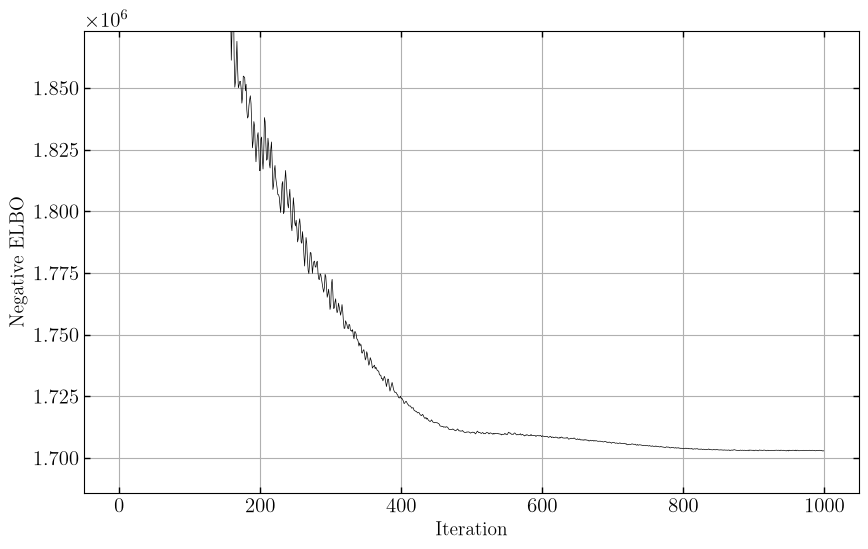

In [10]:
print(bkg_svi_results.losses[-1])
plt.figure(figsize=(10,6))
plt.plot(bkg_svi_results.losses, lw=0.5)
# plt.yscale("log")
plt.ylim(0.99*bkg_svi_results.losses[-1], 1.1*bkg_svi_results.losses[-1])
plt.xlabel('Iteration') ; plt.ylabel('Negative ELBO')
plt.grid()
plt.show()

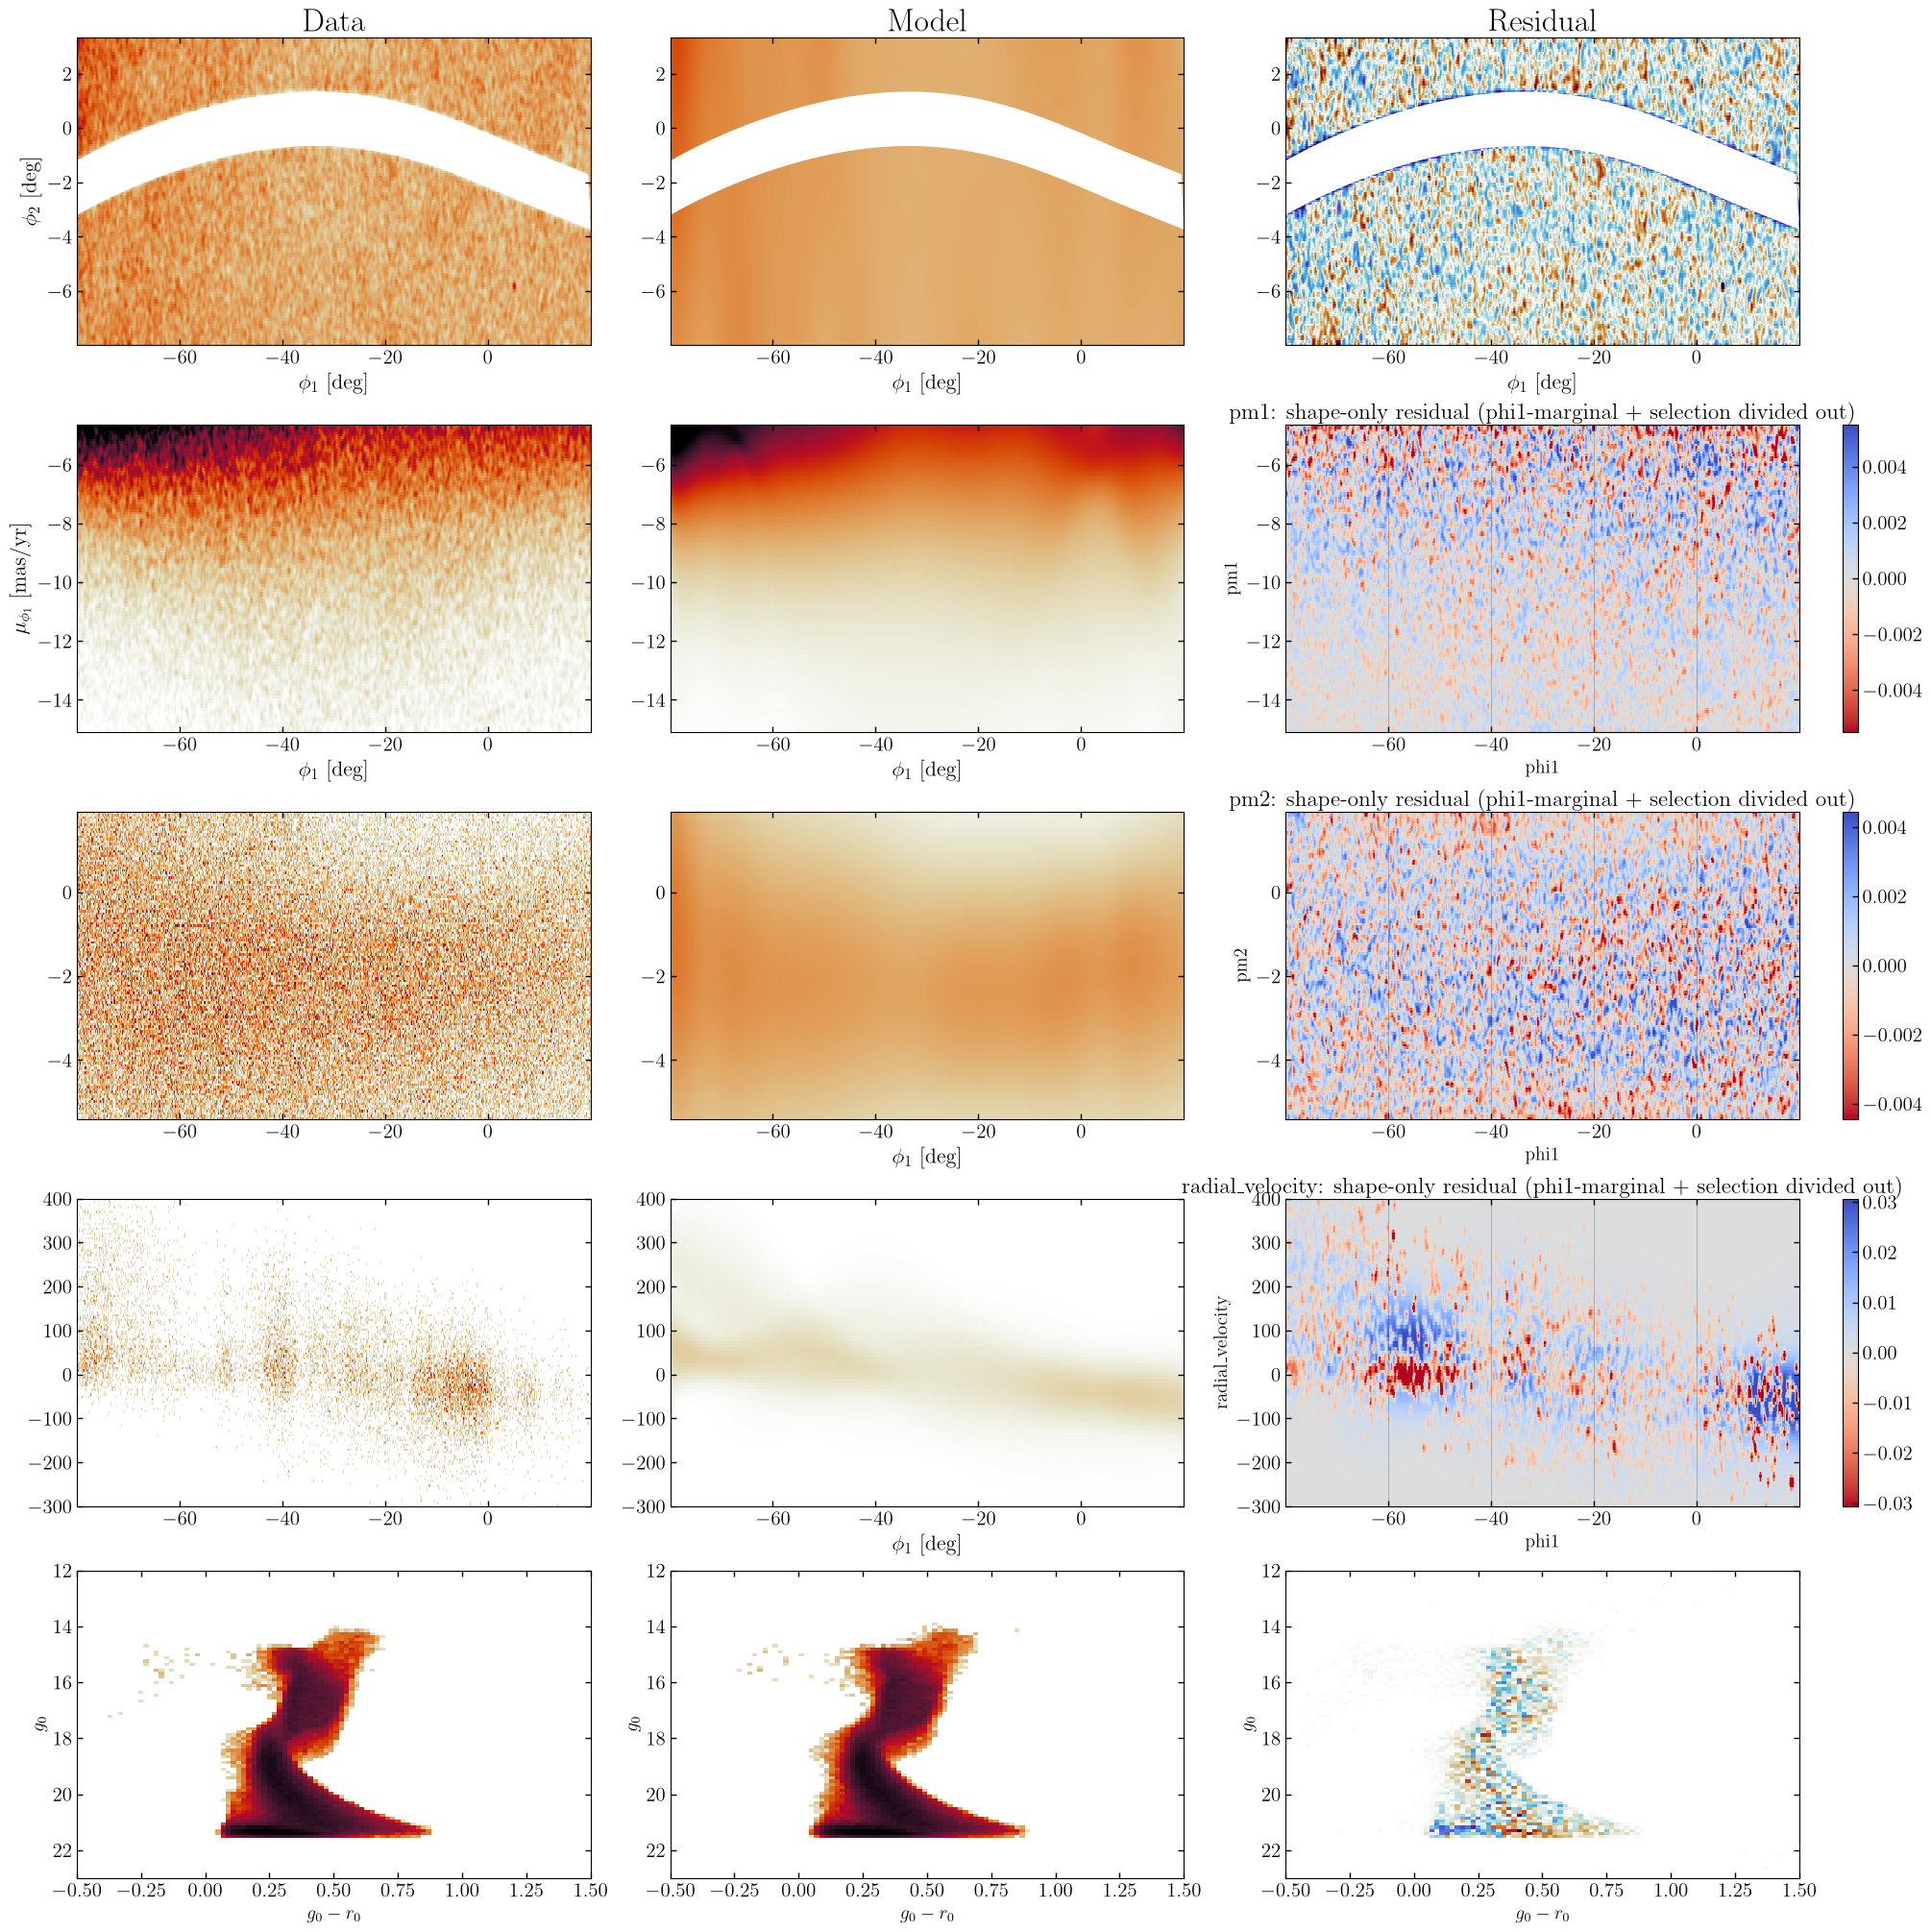

In [11]:
import matplotlib as mpl
fig, axes = plt.subplots(5, 3, figsize=(20, 20), constrained_layout=True)

vmax_phi2 = len(bkg_data['phi1'])*5/(528*128)
vmax = len(bkg_data['pm1'])*5/(528*128)

bkg_x_data = {
    'pm1': init_stream._coord_x(bkg_data, 'pm1'),
    'pm2': init_stream._coord_x(bkg_data, 'pm2'),
    'radial_velocity': init_stream._coord_x(bkg_data, 'radial_velocity'),
}

axes = np.atleast_2d(axes)
plot_data_projections(
    data=bkg_data,
    grids=plot_grids,
    axes=axes[0, 0],
    pcolormesh_kwargs=dict(rasterized=True, vmax=vmax_phi2, vmin=0, cmap=CMAP),
    coord_names=[('phi1', 'phi2')]
)
plot_data_projections(
    data=bkg_data,
    grids=plot_grids,
    axes=axes[1, 0],
    pcolormesh_kwargs=dict(rasterized=True, vmax=vmax, vmin=0, cmap=CMAP),
    coord_names=[('phi1', 'pm1')],
    x_data=bkg_x_data,
)
axes[2,0].hist2d(bkg_x_data['pm2'], bkg_data['pm2'],
                 bins=[512, 128], range=[coord_bounds['phi1'], coord_bounds['pm2']], cmap=CMAP)

axes[3,0].hist2d(bkg_x_data['radial_velocity'], bkg_data['radial_velocity'],
                 bins=[512, 128], range=[[phi1_lim[0],phi1_lim[1]], [-300,400]], cmap=CMAP)

bkg_model.plot_model_projections(ndata=len(bkg_data['pm1']), grids=plot_grids, grid_coord_names=[('phi1', 'pm1')],
                                 pars=bkg_params, axes=axes[1, 1], label=False,
                                 pcolormesh_kwargs=dict(rasterized=True, vmax=vmax, vmin=0, cmap=CMAP))
bkg_model.plot_model_projections(ndata=len(bkg_data['phi1']), grids=plot_grids, grid_coord_names=[('phi1', 'phi2')],
                                 pars=bkg_params, axes=axes[0, 1], label=False,
                                 pcolormesh_kwargs=dict(rasterized=True, vmax=vmax_phi2, vmin=0, cmap=CMAP))
bkg_model.plot_model_projections(ndata=len(bkg_data['pm2']), grids=plot_grids, grid_coord_names=[('phi1', 'pm2')],
                                 pars=bkg_params, axes=axes[2,1], label=False,
                                 pcolormesh_kwargs=dict(rasterized=True, vmax=vmax, vmin=0, cmap=CMAP))
bkg_model.plot_model_projections(ndata=len(bkg_data['radial_velocity']),
                                 grids=plot_grids, grid_coord_names=[('phi1', 'radial_velocity')],
                                 pars=bkg_params, axes=axes[3, 1], label=False,
                                 pcolormesh_kwargs=dict(rasterized=True, vmax=vmax, vmin=0, cmap=CMAP))

bkg_model.plot_residual_projections(
    grids=plot_grids, grid_coord_names=[('phi1', 'phi2')],
    pars=bkg_params,
    data=bkg_data, axes=axes[0, 2], label=False,
    pcolormesh_kwargs=dict(vmin=-vmax_phi2/5, vmax=vmax_phi2/5, cmap=cmr.fusion, rasterized=True)
)

plot_shape_only_residual("pm1", bkg_model, bkg_data, bkg_params, plot_grids, ax=axes[1, 2])
plot_shape_only_residual("pm2", bkg_model, bkg_data, bkg_params, plot_grids, ax=axes[2, 2])
plot_shape_only_residual("radial_velocity", bkg_model, bkg_data, bkg_params, plot_grids, ax=axes[3, 2])

axes[0, 0].set_title('Data', fontsize=24)
axes[0, 1].set_title('Model', fontsize=24)
axes[0, 2].set_title('Residual', fontsize=24)

flow_key, sample_key = jax.random.split(jax.random.key(42))
cmd_dist = CalibratedFlowDensity(flow=cmd_flow, norm_stats=cmd_norm_stats, x=bkg_data["phi1"])
cmd_flow_samples = jax.vmap(lambda k, x: cmd_dist.sample(k, x=x))(
    jax.random.split(sample_key, len(bkg_data['phi1'])), bkg_data["phi1"]
)

H1, xe, ye, = np.histogram2d(bkg_data["PS_g"]-bkg_data["PS_r"], bkg_data["PS_g"], bins=100, range=[[-0.5,1.5], [12, 23]])
H2, _, _    = np.histogram2d(cmd_flow_samples[:, 0] - cmd_flow_samples[:, 1], cmd_flow_samples[:, 0], bins=100, range=[[-0.5,1.5], [12, 23]])
resid = H1-H2
vmax = np.nanmax(np.abs(resid))
axes[4, 0].pcolormesh(xe, ye, H1.T, norm=mpl.colors.LogNorm(), cmap=CMAP, rasterized=True)
axes[4, 1].pcolormesh(xe, ye, H2.T, norm=mpl.colors.LogNorm(), cmap=CMAP, rasterized=True)
axes[4, 2].pcolormesh(xe, ye, resid.T, cmap=cmr.fusion, vmin=-vmax, vmax=vmax, rasterized=True)

for ax in axes[4, :]:
    ax.set_xlabel(r"$g_0-r_0$")
    ax.set_ylabel(r"$g_0$")
    ax.invert_yaxis()

axes[3,1].set_ylim(-300, 400) ; axes[3,2].set_ylim(-300, 400)

blank = cmr.take_cmap_colors(CMAP, N=2, return_fmt='hex')[0]
for ax in axes[0,:]:
    patch_sky = mpl.patches.Polygon(
            iso_obj.pawprint.skyprint["stream"].vertices[::50],
            facecolor=blank,
            alpha=1
        )
    ax.add_patch(patch_sky)

plt.show()


## Stage 2: Stream model

Now includes the fixed single-stellar-population (SSP) isochrone CMD term
(`IsochroneCMD`, conditional on `stream_isochrone` having been loaded above)
in addition to `phi1, phi2, pm1, pm2, rv`. Uses the current
`make_stream_model_component` signature, which requires `rv_min`/`rv_max`
computed from the stream data's radial-velocity coverage.


In [12]:

stream_filename = SVI_RESULTS_DIR / "stream_{}_{}_{}_{}_{}_auto_normal.pkl".format(*STREAM_KNOT_SPACINGS)

_d = try_load_cached(stream_filename)
if _d is not None:
    print(f"Loaded cached stream SVI result from {stream_filename}")
    stream_svi_results, stream_guide = _d["svi_results"], _d["guide"]
else:
    stream_phi1_knots = stream_model.coord_parameters["phi1"]["locs"][0]
    stream_phi2_knots = stream_model.coord_parameters["phi2"]["knots"]
    stream_pm1_knots = stream_model.coord_parameters["pm1"]["knots"]
    stream_pm2_knots = stream_model.coord_parameters["pm2"]["knots"]
    stream_rv_knots = stream_model.coord_parameters["radial_velocity"]["knots"]

    _interp_dict = init_stream.interpolate_stream_tracks(stream_data, phi1_lim)
    eval_interp_phi2 = jnp.array(_interp_dict["phi2"](stream_phi2_knots)+2)
    eval_interp_pm1 = jnp.array(_interp_dict["pm1"](stream_pm1_knots)+2)
    eval_interp_pm2 = jnp.array(_interp_dict["pm2"](stream_pm2_knots)+2)
    eval_interp_rv = jnp.array(_interp_dict["radial_velocity"](stream_rv_knots)+2)

    stream_init_params = {
        "phi1": {
            "mixing_distribution": jnp.ones(len(stream_phi1_knots)) / len(stream_phi1_knots),
            "scales": jnp.full(stream_phi1_knots.shape[0], STREAM_KNOT_SPACINGS[0]),
        },
        "phi2": {"loc_vals": eval_interp_phi2, "scale_vals": jnp.full(stream_phi2_knots.shape[0], 0.5)},
        "pm1": {"loc_vals": eval_interp_pm1, "scale_vals": jnp.full(stream_pm1_knots.shape[0], 0.35)},
        "pm2": {"loc_vals": eval_interp_pm2, "scale_vals": jnp.full(stream_pm2_knots.shape[0], 0.35)},
        "radial_velocity": {"loc_vals": eval_interp_rv, "scale_vals": jnp.full(stream_rv_knots.shape[0], 4)},
    }

    print(f"Fitting stream model ({NUM_STEPS['stream']} SVI steps)...")
    stream_svi_results, stream_guide = run_SVI(
        stream_model, stream_init_params, stream_data, stream_data_err,
        num_steps=20_000, adaptive_lr=True, init_lr=1e-2, num_particles=3,
    )
    save_svi_result(stream_filename, stream_svi_results, stream_guide)

stream_params = get_svi_params(model=stream_model, data=stream_data, svi_results=stream_svi_results, guide=stream_guide)
print("final ELBO loss:", stream_svi_results.losses[-1])
        

Loaded cached stream SVI result from /Users/Tavangar/Work/gd1-dr3/svi_results/flow_test/stream_5_10_10_10_10_auto_normal.pkl
final ELBO loss: 16845.628462059776


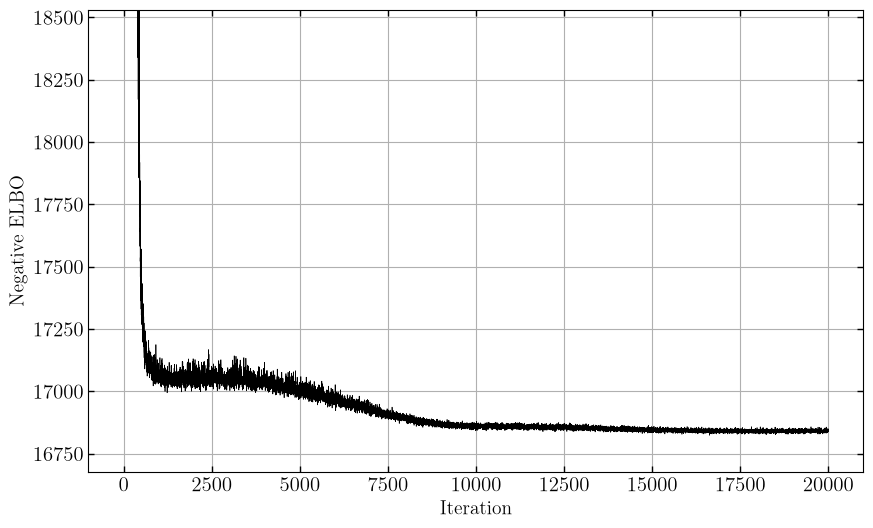

In [13]:
plt.figure(figsize=(10,6))
plt.plot(stream_svi_results.losses, lw=0.5)
# plt.yscale("log")
plt.ylim(0.99*stream_svi_results.losses[-1], 1.1*stream_svi_results.losses[-1])
plt.xlabel('Iteration') ; plt.ylabel('Negative ELBO')
plt.grid()
plt.show()

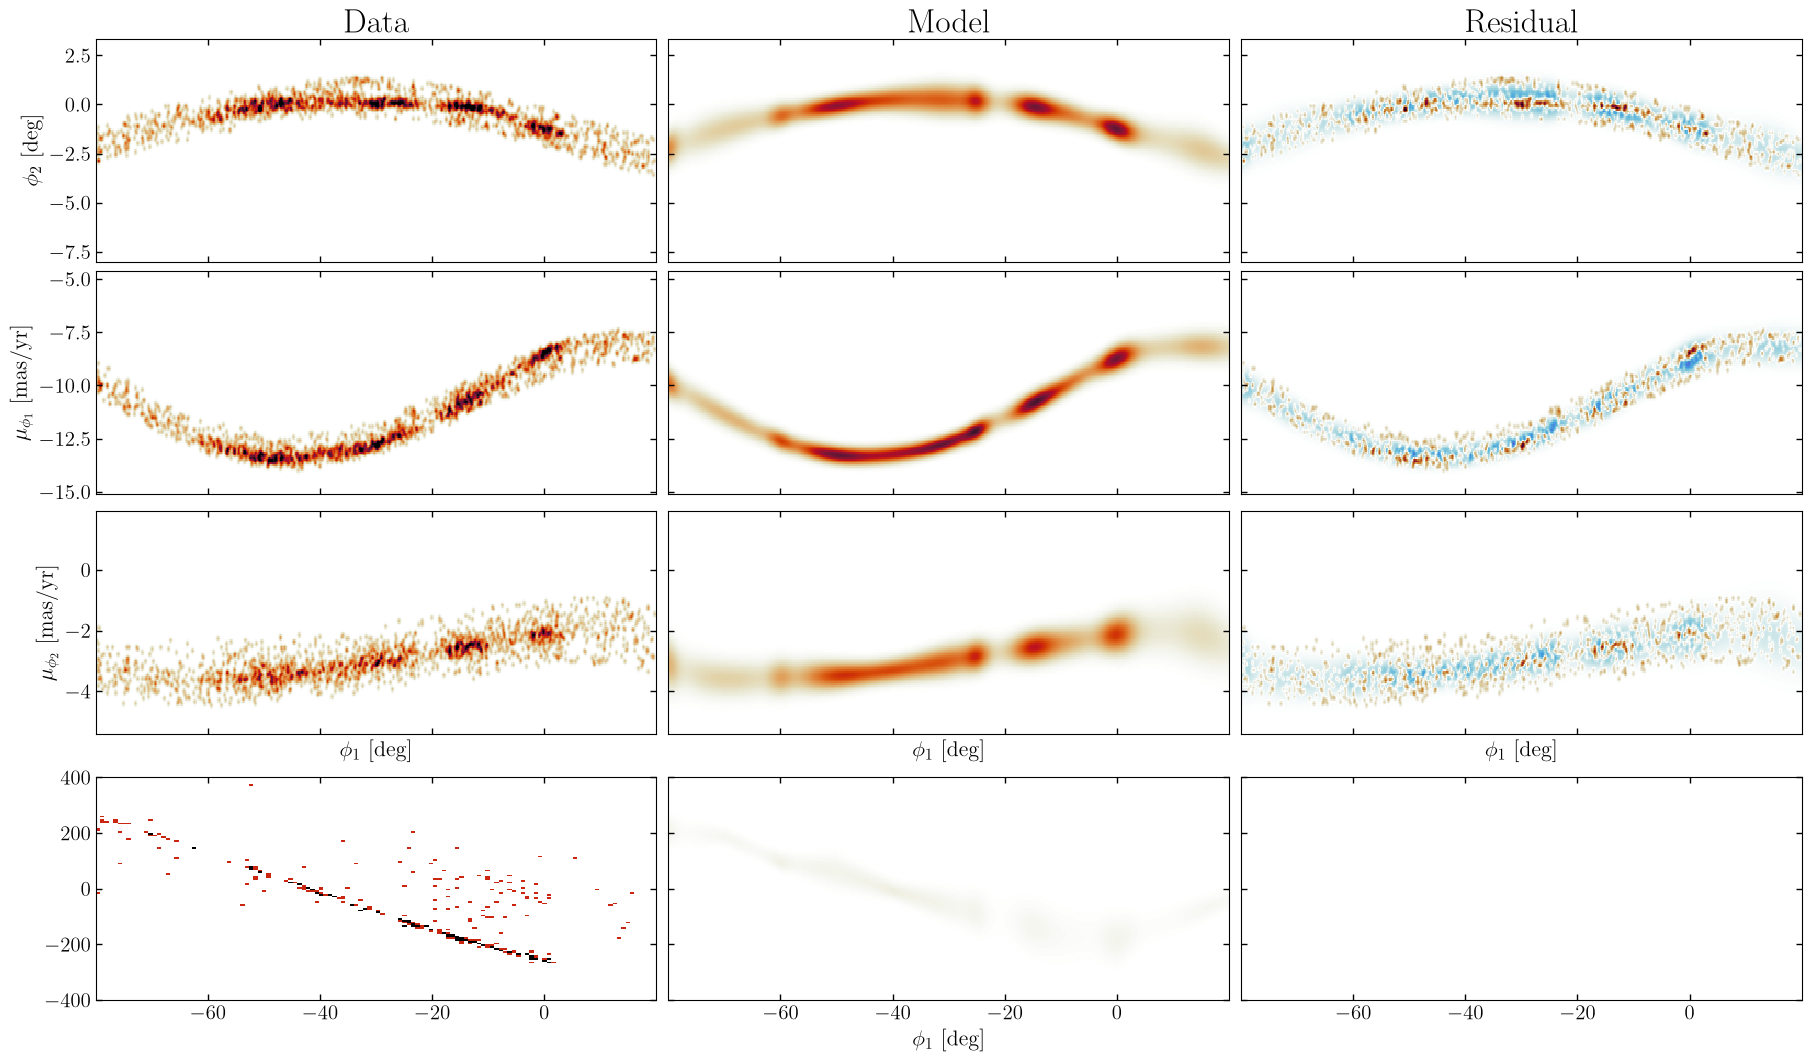

In [14]:

fig, axes = plt.subplots(
    4,
    3,
    figsize=(18, 3.5 * 3),
    sharex=True,
    sharey="row",
    constrained_layout=True,
)

axes = np.atleast_2d(axes)

# pm1/pm2 are ragged (not every star has a valid proper motion), so their own
# valid-star phi1 subsample -- not stream_data["phi1"] -- is needed both for
# histogramming (x_data=) and for expected-count scaling (ndata=). phi2 is
# never ragged, so it keeps using stream_data["phi1"]/len(stream_data["phi1"]) directly.
stream_x_data = {
    "pm1": init_stream._coord_x(stream_data, "pm1"),
    "pm2": init_stream._coord_x(stream_data, "pm2"),
}


plot_data_projections(
    data=stream_data,
    grids=plot_grids,
    coord_names=[('phi1','phi2'), ('phi1', 'pm1'), ('phi1', 'pm2')],
    axes=axes[:3, 0],
    pcolormesh_kwargs=dict(rasterized=True, vmax=1, vmin=0, cmap=CMAP),
    x_data=stream_x_data,
    # coord_names=GD1BackgroundModel.coord_names,
)
axes[3,0].hist2d(init_stream._coord_x(stream_data, 'radial_velocity'), stream_data['radial_velocity'], bins=[128, 128],
                 range=[[phi1_lim[0],phi1_lim[1]], [-400,400]], cmap=CMAP, vmax=2, vmin=0)


stream_model.plot_model_projections(
    ndata={'phi2': len(stream_data['phi1']), 'pm1': len(stream_data['pm1']), 'pm2': len(stream_data['pm2'])},
    grids=plot_grids, grid_coord_names=[('phi1','phi2'), ('phi1', 'pm1'), ('phi1', 'pm2')],
    pars=stream_params, axes=axes[:3, 1], label=False,
    pcolormesh_kwargs=dict(rasterized=True, vmax=1, vmin=0, cmap=CMAP))
stream_model.plot_model_projections(ndata=len(stream_data['radial_velocity']), grids=plot_grids, grid_coord_names=[('phi1','radial_velocity')],
                                    pars=stream_params, axes=axes[3, 1], label=False,
                                    pcolormesh_kwargs=dict(rasterized=True, vmax=2, vmin=0, cmap=CMAP))

stream_model.plot_residual_projections(
    grids=plot_grids, pars=stream_params, grid_coord_names=[('phi1','phi2'), ('phi1', 'pm1'), ('phi1', 'pm2')],
    data=stream_data, axes=axes[:3, 2], label=False,
    pcolormesh_kwargs=dict(vmin=-1, vmax=1, cmap=RESID_CMAP, rasterized=True),
    x_data=stream_x_data,
)

axes[3,0].set_ylim(-400, 400)
axes[0,0].set_title('Data', fontsize=24)
axes[0,1].set_title('Model', fontsize=24)
axes[0,2].set_title('Residual', fontsize=24)
plt.show()



### Stream CMD diagnostic

Visualizes the fitted `IsochroneCMD` term (see `scripts/plot_stream_cmd.py`):
the stream data's CMD with the fitted isochrone ridge line overlaid at a
few representative `phi1` values (showing the distance-modulus gradient
along the stream), the fitted vs. fixed Valluri+24 distance-modulus
track, and `IsochroneCMD` posterior samples vs. the real data as a sanity
check. No membership probabilities are available yet at this standalone
stage (`stream_data` is already a stream-only selection), so all points
are plotted un-colored/un-filtered.


In [15]:
import importlib
importlib.reload(sys.modules['plot_stream_cmd'])
from plot_stream_cmd import plot_stream_cmd_fit

In [16]:
if init_stream.CMD_COORD in stream_model.coord_distributions:
    cmd_dist = stream_model.make_dists(stream_params)[init_stream.CMD_COORD]
    print(cmd_dist.dm_offset)
    print(cmd_dist.color_offset)
    print(cmd_dist.color_scale)
else:
    print("stream_model has no CMD term -- skipping.")

0.0005934234506828062
0.09052215940409664
0.08859855197030046


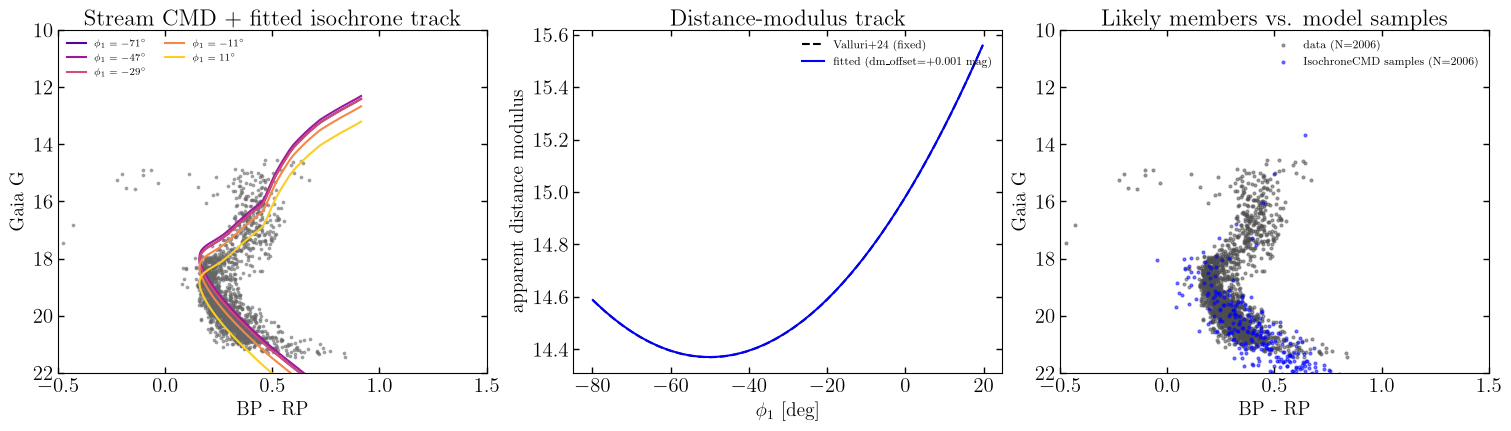

In [17]:

from plot_stream_cmd import plot_stream_cmd_fit

if stream_isochrone is not None:
    plot_stream_cmd_fit(stream_model, stream_params, stream_data)
    plt.show()
else:
    print("No stream_isochrone loaded -- skipping CMD diagnostic (see 'Load the stream SSP isochrone CMD track' above).")



## Stage 3: Background + stream mixture model

Refit jointly on `run_data` (the full candidate-member sample), starting
from the two single-component fits above.

**A note on memory (SMOKE_TEST sandboxes):** this stage (and Stage 4) JIT-
compile a substantially larger combined model than either single-component
fit above, since `ComponentMixtureModel` traces both components' log-
densities together. In a very memory-constrained environment (this
particular sandbox has ~4GB RAM and no swap), that compile step alone can
exceed available memory and get OOM-killed, even after shrinking the data,
`num_particles`, knot counts, and `N_MIXTURE` -- i.e. this is a hardware
ceiling in this specific sandbox, not a bug in the model-combination logic
itself (which is an unmodified port of the existing, working pattern in
`run_full_gd1_model.py` / `5-AutoNormal_SVI.ipynb`, and doesn't involve the
new CMD flow term at all -- see the note in the intro above). Stages 1-2
(which do exercise the new CMD flow term) were verified end-to-end in this
sandbox via `jupyter nbconvert --execute`. On your own machine (more RAM,
`HAVE_CATS=True`), Stages 3-4 should run the same way they already do in the
reference pipeline.


In [18]:
if "bkg_params" not in globals() or "stream_params" not in globals():
    _bkg_cached = try_load_cached(bkg_filename)
    _stream_cached = try_load_cached(stream_filename)
    if _bkg_cached is not None and _stream_cached is not None:
        bkg_params = get_svi_params(
            model=bkg_model, data=bkg_data,
            svi_results=_bkg_cached["svi_results"], guide=_bkg_cached["guide"],
        )
        stream_params = get_svi_params(
            model=stream_model, data=stream_data,
            svi_results=_stream_cached["svi_results"], guide=_stream_cached["guide"],
        )
    else:
        print("No cached bkg/stream SVI results found -- skipping combined bkg+stream fit.")

In [19]:
def _drop_modeldata(nested_pars):
    """Drop each coordinate's ':modeldata' latent -- it's a per-star array
    sized to the *standalone* Stage 1/2 fit's data, not to `run_data`, so
    reusing it here would try to init the joint model's differently-sized
    modeldata site with an array of the wrong length."""
    return {
        coord: {arg: v for arg, v in sub_pars.items() if arg != "modeldata"}
        for coord, sub_pars in nested_pars.items()
    }

In [20]:

bkg_stream_filename = SVI_RESULTS_DIR / "mm_bkg{}_{}_{}_{}_stream{}_{}_{}_{}_{}_auto_normal.pkl".format(
    *jnp.concatenate([BKG_KNOT_SPACINGS, STREAM_KNOT_SPACINGS])
)

# _d = None#try_load_cached(bkg_stream_filename)
# if _d is not None:
#     print(f"Loaded cached background+stream SVI result from {bkg_stream_filename}")
#     no_off_svi_results, no_off_guide = _d["svi_results"], _d["guide"]
# else:
#     f_stream = jnp.around(len(stream_data['phi1']) / len(run_data['phi1']), 3)

#     # filtered_bkg = {k: v for k, v in bkg_svi_results.params.items() if "modeldata" not in k}
#     # filtered_stream = {k: v for k, v in stream_svi_results.params.items() if "modeldata" not in k}
#     # packed_params = filtered_bkg | filtered_stream
#     # packed_params["mixture-probs"] = jnp.array([1 - f_stream, f_stream])

#     packed_params = stream_bkg_mm.pack_params({
#         bkg_model_mm.name: _drop_modeldata(bkg_params),
#         stream_model_mm.name: _drop_modeldata(stream_params),
#     })
#     packed_params["mixture-probs"] = jnp.array([1 - f_stream, f_stream])
    # Note: `mixture:modeldata_*` is a bookkeeping/nuisance site introduced by
    # ComponentMixtureModel itself (not present in either single-component
    # fit, since those were fit as standalone ModelComponents). We don't set
    # it explicitly here -- numpyro's `init_to_value` falls back to its
    # default init strategy for any site missing from `init_params`, which is
    # fine for a nuisance site like this one. (run_full_gd1_model.py's `main`
    # instead seeds it from a previously cached full-mixture fit, which this
    # notebook doesn't assume exists.)

#     print(f"Fitting background+stream mixture model ({NUM_STEPS['bkg_stream']} SVI steps)...")
#     no_off_svi_results, no_off_guide = run_SVI(
#         stream_bkg_mm, packed_params, run_data, run_data_err,
#         num_steps=10_000, adaptive_lr=True, init_lr=5e-2, num_particles=3,
#     )
#     save_svi_result(bkg_stream_filename, no_off_svi_results, no_off_guide)

# no_off_params = get_svi_params(model=stream_bkg_mm, data=run_data, svi_results=no_off_svi_results, guide=no_off_guide)
# print("final ELBO loss:", no_off_svi_results.losses[-1])
# print("fitted mixture-probs [bkg, stream]:", no_off_params["mixture-probs"])


In [21]:
_d = None#try_load_cached(bkg_stream_filename)
if _d is not None:
    print(f"Loaded cached background+stream SVI result from {bkg_stream_filename}")
    no_off_svi_results, no_off_guide = _d["svi_results"], _d["guide"]
else:
    f_stream = jnp.around(len(stream_data['phi1']) / len(run_data['phi1']), 3)

    packed_params = stream_bkg_mm.pack_params({
        bkg_model_mm.name: _drop_modeldata(bkg_params),
        stream_model_mm.name: _drop_modeldata(stream_params),
    })
    packed_params["mixture-probs"] = jnp.array([1 - f_stream, f_stream])
    # # Freeze every param at its current packed_params value except mixture-probs.
    frozen_names = [k for k in packed_params if k != "mixture-probs"]
    fixed_values = {k: v for k, v in packed_params.items() if k != "mixture-probs"}

    def frozen_stream_bkg_mm(data, err=None):
        with numpyro.handlers.block(hide=frozen_names), numpyro.handlers.substitute(data=fixed_values):
            stream_bkg_mm(data, err=err)

    mixprobs_only_init = {"mixture-probs": packed_params["mixture-probs"]}

    print(f"Fitting background+stream mixture model ({NUM_STEPS['bkg_stream']} SVI steps)...")
    no_off_svi_results, no_off_guide = run_SVI(
        frozen_stream_bkg_mm, mixprobs_only_init, run_data, run_data_err,
        num_steps=2_000, adaptive_lr=True, init_lr=1e-2, num_particles=3,
    )

    save_svi_result(bkg_stream_filename, no_off_svi_results, no_off_guide)

# mixture-probs is the only thing that could have moved, so splicing the
# fitted value back into packed_params gives the full fitted param dict.
fitted_probs = jnp.median(
    Predictive(no_off_guide, params=no_off_svi_results.params, num_samples=200)(
        jax.random.PRNGKey(0), data=run_data,
    )["mixture-probs"],
    axis=0,
)

mixprobs_only_params = dict(packed_params)
mixprobs_only_params["mixture-probs"] = fitted_probs
no_off_params = stream_bkg_mm.expand_numpyro_params(mixprobs_only_params)

Fitting background+stream mixture model (5000 SVI steps)...


100%|██████████| 2000/2000 [02:42<00:00, 12.30it/s, init loss: 2376209566.9555, avg. loss [1901-2000]: 2143307.4498]


In [27]:
print("final ELBO loss:", no_off_svi_results.losses[-1])
print("naive f_stream:          ", float(f_stream))
print("init mixture-probs:      ", packed_params["mixture-probs"])
print("fitted mixture-probs:    ",fitted_probs, " (everything else frozen)")

final ELBO loss: 2143262.3138153856
naive f_stream:           0.01
init mixture-probs:       [0.99 0.01]
fitted mixture-probs:     [0.99259473 0.00740527]  (everything else frozen)


N(bkg selection)    = 157058
N(stream selection) = 2006
N(run/candidate)    = 192495
naive f_stream = N(stream selection)/N(run) = 0.010000  <- used to init mixture-probs
fitted mixture-probs [bkg, stream]           = [0.99259473 0.00740527]
fitted stream fraction                       = 0.007405


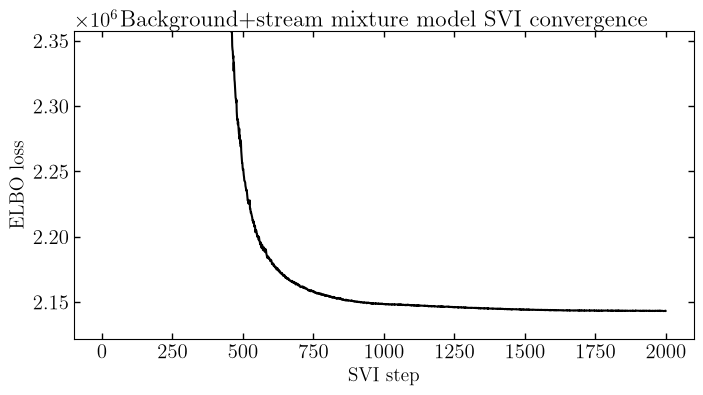

In [23]:
# --- Stage 3 diagnostics: is the fitted stream fraction sane? ---

# `f_stream` is only defined if Stage 3 was freshly fit (not loaded from
# cache) -- recompute it here so this cell works either way.
if "f_stream" not in globals():
    f_stream = jnp.around(len(stream_data_) / len(run_data_), 3)

n_bkg, n_stream, n_run = len(bkg_data["phi1"]), len(stream_data["phi1"]), len(run_data["phi1"])
fitted_mixture_probs = no_off_params["mixture-probs"]

print(f"N(bkg selection)    = {n_bkg}")
print(f"N(stream selection) = {n_stream}")
print(f"N(run/candidate)    = {n_run}")
print(f"naive f_stream = N(stream selection)/N(run) = {float(f_stream):.6f}  <- used to init mixture-probs")
print(f"fitted mixture-probs [bkg, stream]           = {fitted_mixture_probs}")
print(f"fitted stream fraction                       = {float(fitted_mixture_probs[1]):.6f}")

plt.figure(figsize=(8, 4))
plt.plot(no_off_svi_results.losses)
plt.ylim(0.99 * no_off_svi_results.losses[-1], 1.1 * no_off_svi_results.losses[-1])
plt.xlabel("SVI step")
plt.ylabel("ELBO loss")
plt.title("Background+stream mixture model SVI convergence")
plt.show()

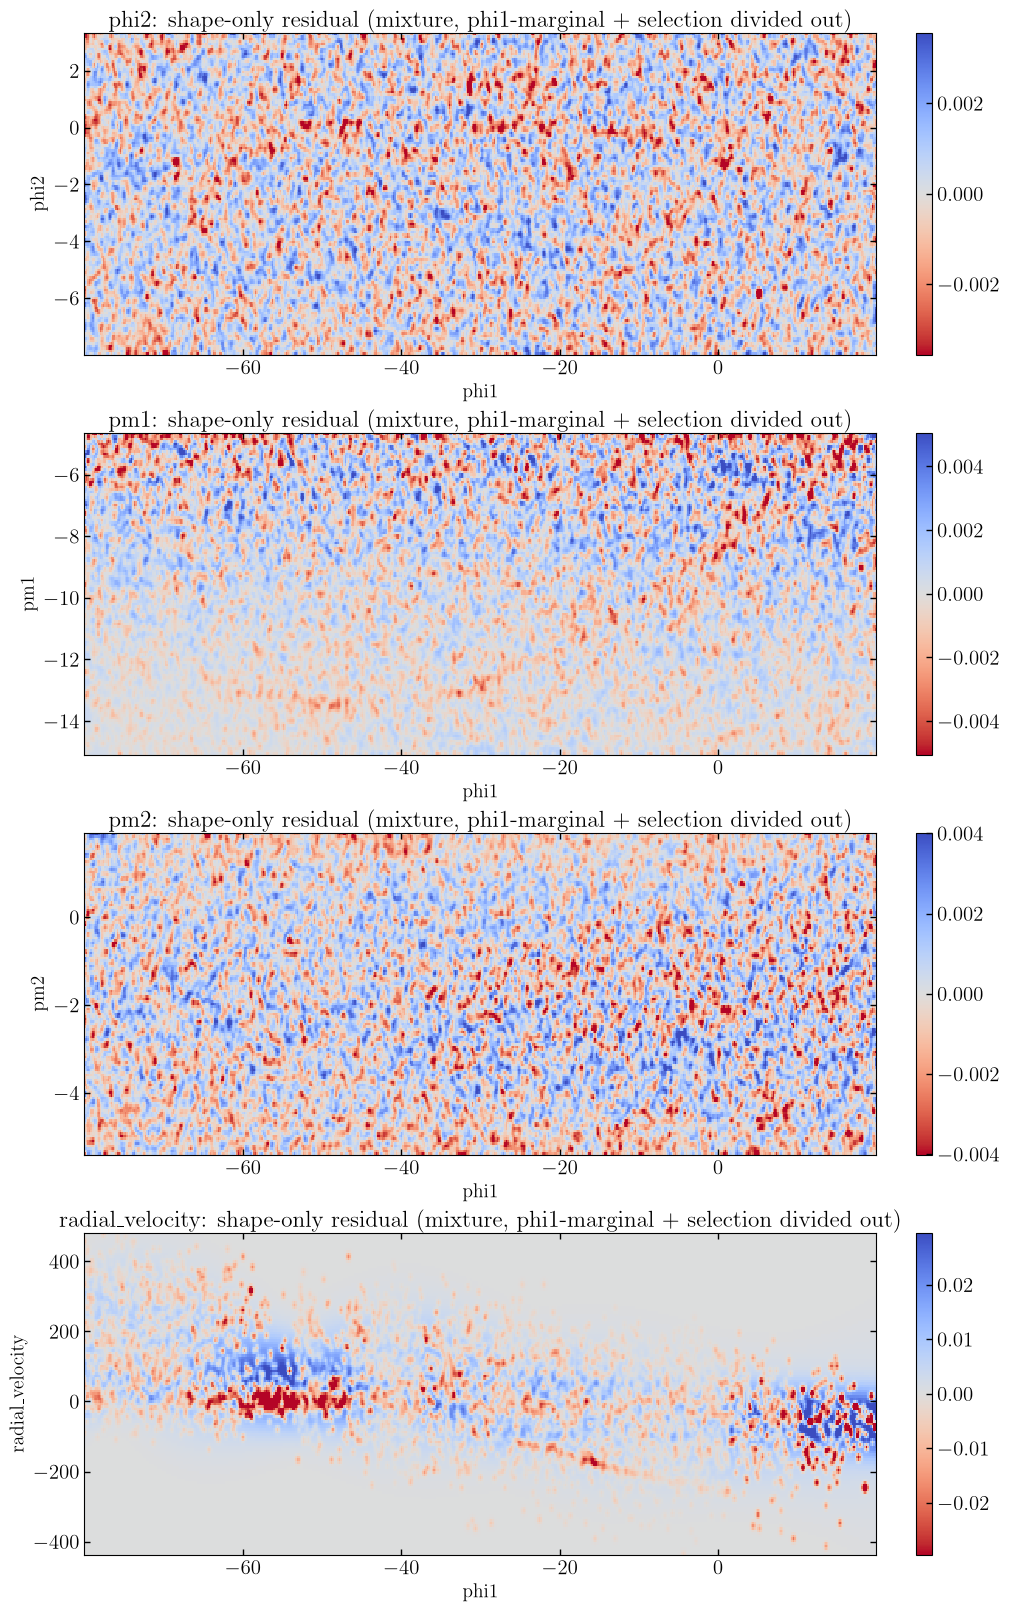

In [24]:
fig, axes = plt.subplots(4, 1, figsize=(10, 16), constrained_layout=True)
for ax, coord in zip(axes, ["phi2", "pm1", "pm2", "radial_velocity"]):
    plot_shape_only_residual_mixture(
        coord, stream_bkg_mm, run_data, no_off_params, plot_grids, ax=ax,
    )
plt.show()

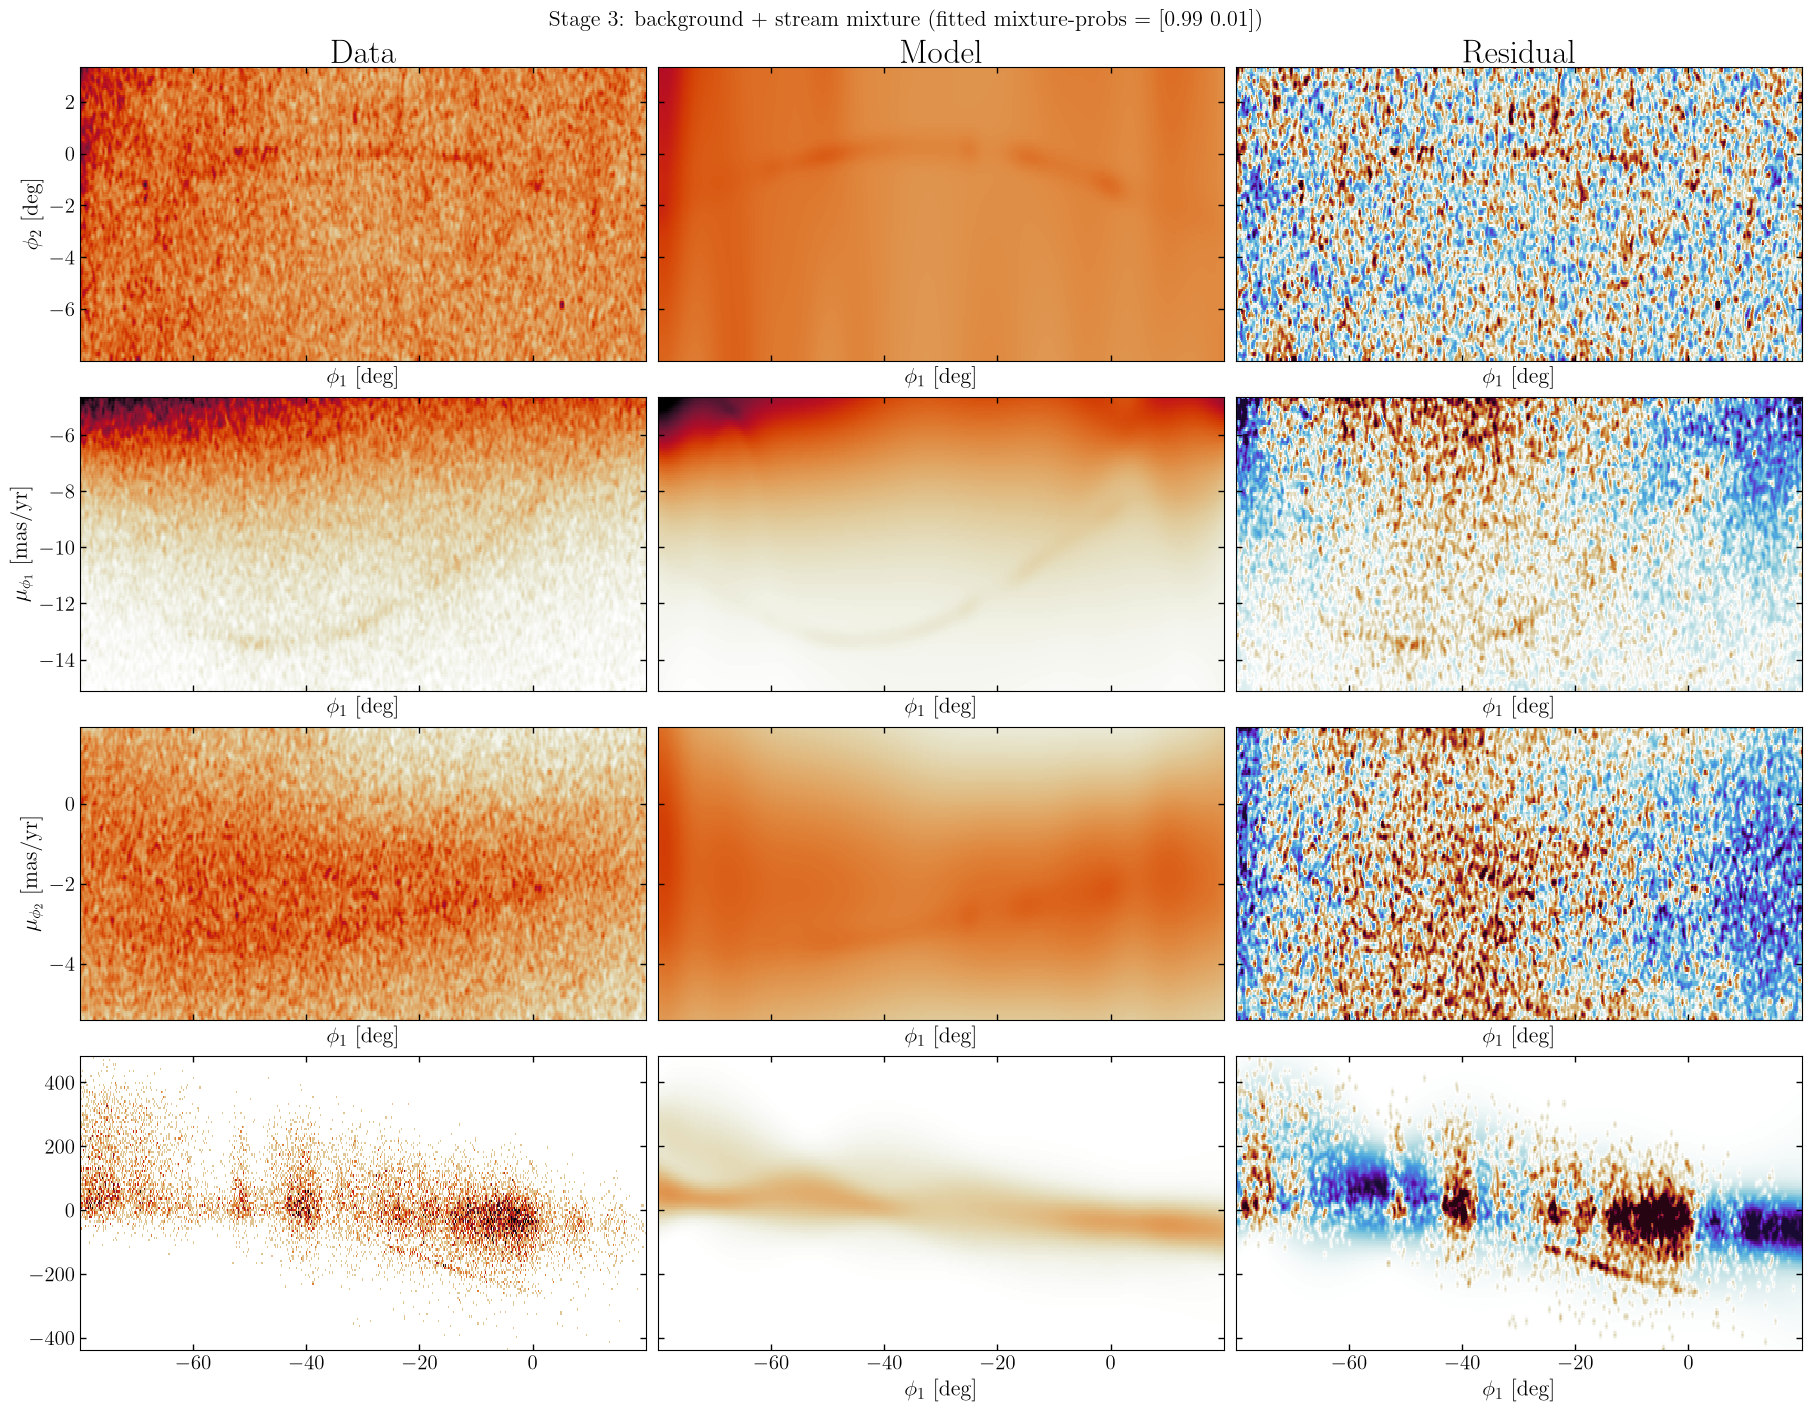

In [25]:
# --- Data / Model / Residual grid for the Stage 3 (bkg+stream) mixture ---

stage3_x_data = {
    "pm1": init_stream._coord_x(run_data, "pm1"),
    "pm2": init_stream._coord_x(run_data, "pm2"),
    "radial_velocity": init_stream._coord_x(run_data, "radial_velocity"),
}
stage3_ndata = {
    "phi2": len(run_data["phi1"]),
    "pm1": len(run_data["pm1"]),
    "pm2": len(run_data["pm2"]),
    "radial_velocity": len(run_data["radial_velocity"]),
}

def _row_vmax(x, y, xgrid, ygrid, pct=99.5):
    H, *_ = np.histogram2d(x, y, bins=[xgrid, ygrid])
    return np.percentile(H[H > 0], pct) if np.any(H > 0) else 1.0

stage3_row_vmax = {
    "phi2": _row_vmax(run_data["phi1"], run_data["phi2"], plot_grids["phi1"], plot_grids["phi2"]),
    "pm1": _row_vmax(stage3_x_data["pm1"], run_data["pm1"], plot_grids["phi1"], plot_grids["pm1"]),
    "pm2": _row_vmax(stage3_x_data["pm2"], run_data["pm2"], plot_grids["phi1"], plot_grids["pm2"]),
    "radial_velocity": _row_vmax(
        stage3_x_data["radial_velocity"], run_data["radial_velocity"],
        plot_grids["phi1"], plot_grids["radial_velocity"],
    ),
}

fig, axes = plt.subplots(
    4, 3, figsize=(18, 3.5 * 4), sharex=True, sharey="row", constrained_layout=True,
)
axes = np.atleast_2d(axes)

# --- Data column ---
plot_data_projections(
    data=run_data, grids=plot_grids, axes=axes[0, 0], coord_names=[("phi1", "phi2")],
    pcolormesh_kwargs=dict(rasterized=True, vmax=stage3_row_vmax["phi2"], vmin=0, cmap=CMAP),
)
plot_data_projections(
    data=run_data, grids=plot_grids, axes=axes[1, 0], coord_names=[("phi1", "pm1")],
    pcolormesh_kwargs=dict(rasterized=True, vmax=stage3_row_vmax["pm1"], vmin=0, cmap=CMAP),
    x_data=stage3_x_data,
)
plot_data_projections(
    data=run_data, grids=plot_grids, axes=axes[2, 0], coord_names=[("phi1", "pm2")],
    pcolormesh_kwargs=dict(rasterized=True, vmax=stage3_row_vmax["pm2"], vmin=0, cmap=CMAP),
    x_data=stage3_x_data,
)
axes[3, 0].hist2d(
    stage3_x_data["radial_velocity"], run_data["radial_velocity"],
    bins=[plot_grids["phi1"], plot_grids["radial_velocity"]],
    cmap=CMAP, vmax=stage3_row_vmax["radial_velocity"], vmin=0,
)

# --- Model column (stream_bkg_mm = Stage 3 bkg + stream mixture) ---
for row, coord in enumerate(["phi2", "pm1", "pm2", "radial_velocity"]):
    stream_bkg_mm.plot_model_projections(
        ndata=stage3_ndata[coord], grids=plot_grids, grid_coord_names=[("phi1", coord)],
        pars=no_off_params, axes=axes[row, 1], label=False,
        pcolormesh_kwargs=dict(rasterized=True, vmax=stage3_row_vmax[coord], vmin=0, cmap=CMAP),
    )

# --- Residual column (model expected counts - data counts) ---
for row, coord in enumerate(["phi2", "pm1", "pm2", "radial_velocity"]):
    v = stage3_row_vmax[coord] / 5
    stream_bkg_mm.plot_residual_projections(
        grids=plot_grids, grid_coord_names=[("phi1", coord)], pars=no_off_params,
        data=run_data, axes=axes[row, 2], label=False,
        pcolormesh_kwargs=dict(vmin=-v, vmax=v, cmap=RESID_CMAP, rasterized=True),
        x_data=stage3_x_data,
    )

axes[3, 1].set_ylim(coord_bounds["radial_velocity"])
axes[3, 2].set_ylim(coord_bounds["radial_velocity"])
axes[0, 0].set_title("Data", fontsize=24)
axes[0, 1].set_title("Model", fontsize=24)
axes[0, 2].set_title("Residual", fontsize=24)
fig.suptitle(
    f"Stage 3: background + stream mixture (fitted mixture-probs = {packed_params['mixture-probs']})",
    fontsize=16,
)
plt.show()

N(p(stream) > 0.50) = 1708 / 192495 (0.0089 of run_data)
Compare to fitted global mixture weight: 0.0074


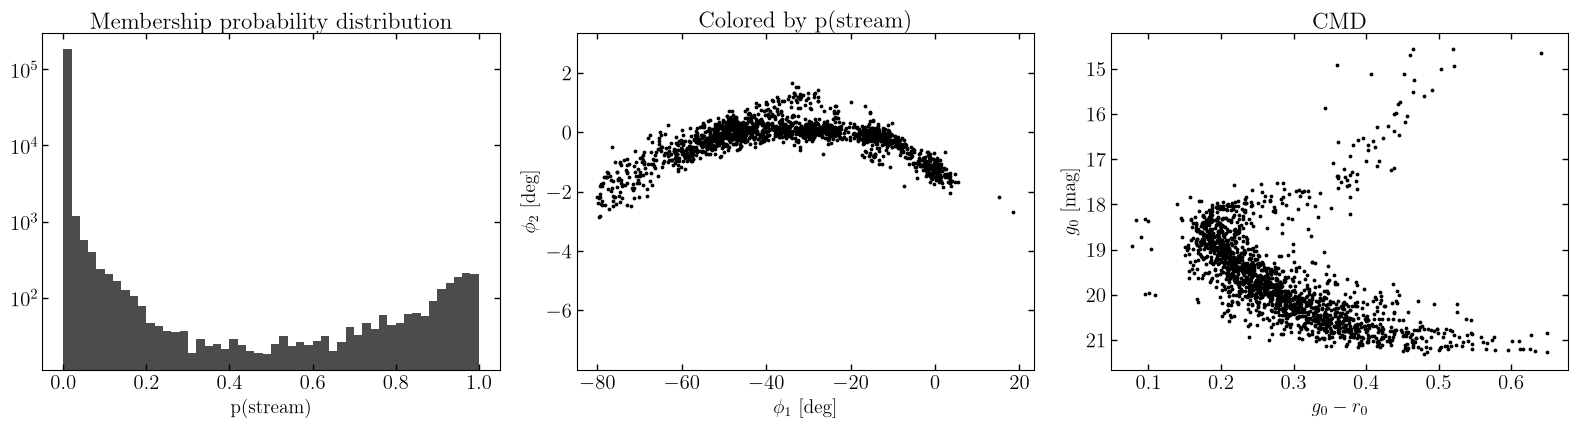

In [29]:
# --- Per-star Stage 3 membership probabilities ---
from plot_stream_cmd import compute_membership_probs

stage3_membership = compute_membership_probs(stream_bkg_mm, run_data, run_data_err, no_off_params)

cutoff = 0.5
likely_members = (stage3_membership["stream"] > cutoff) & (run_data['PS_g'] < 21.5)
n_likely = int(likely_members.sum())
print(f"N(p(stream) > {cutoff:.2f}) = {n_likely} / {len(run_data['phi1'])} "
      f"({n_likely / len(run_data['phi1']):.4f} of run_data)")
print(f"Compare to fitted global mixture weight: {float(no_off_params['mixture-probs'][1]):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].hist(stage3_membership["stream"], bins=50, alpha=0.7)
axes[0].set_yscale("log")
axes[0].set_xlabel("p(stream)")
axes[0].set_title("Membership probability distribution")

sc = axes[1].scatter(
    run_data["phi1"][likely_members], run_data["phi2"][likely_members],# c=stage3_membership["stream"],
    s=3, #cmap=CMAP, vmin=0, vmax=0.0001, rasterized=True,
)
axes[1].set_xlabel(r"$\phi_1$ [deg]")
axes[1].set_ylabel(r"$\phi_2$ [deg]")
axes[1].set_title("Colored by p(stream)")
axes[1].set_ylim(coord_bounds["phi2"])
# plt.colorbar(sc, ax=axes[1], label="p(stream)")

axes[2].scatter(
    run_data["PS_g"][likely_members] - run_data["PS_r"][likely_members], run_data["PS_g"][likely_members],# c=stage3_membership["stream"],
    s=3, #cmap=CMAP, vmin=0, vmax=0.0001, rasterized=True,
)
axes[2].invert_yaxis()
axes[2].set_xlabel(r"$g_0 - r_0$")
axes[2].set_ylabel(r"$g_0$ [mag]")
axes[2].set_title("CMD")
plt.tight_layout()
plt.show()

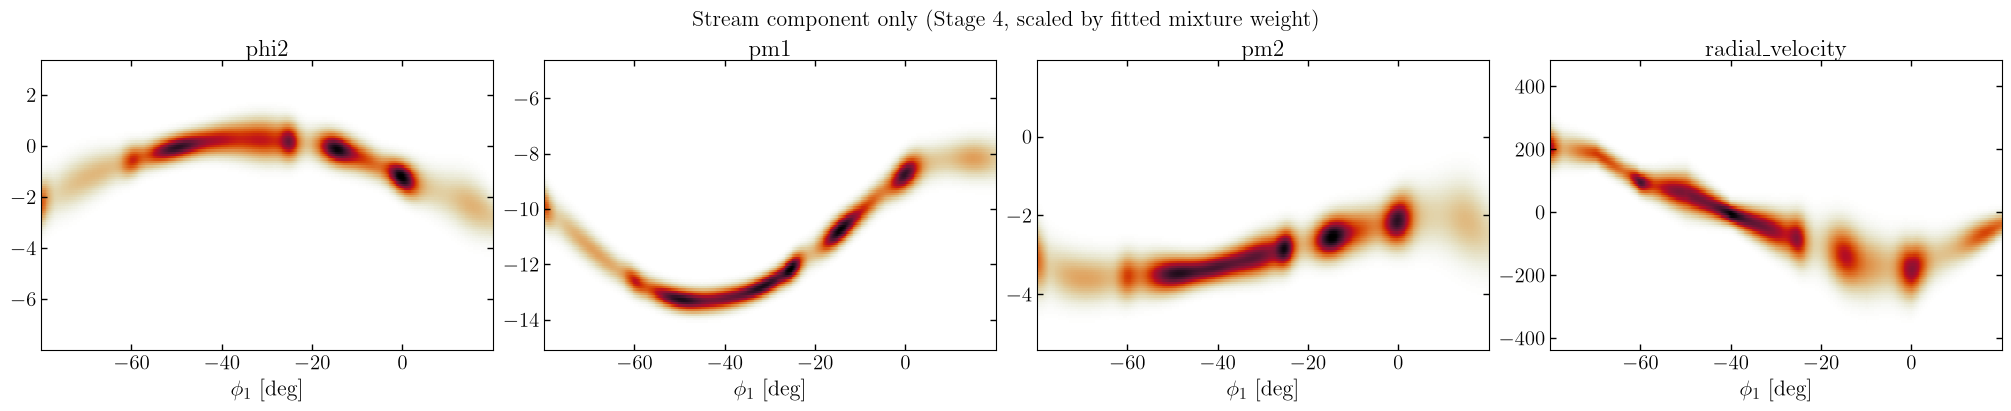

In [30]:
# Isolate just the stream component's model density from the joint fit.
# stream_model_mm's own log_prob always integrates to 1 (it's a single
# ModelComponent, not the full mixture), so scale by the *fitted* stream
# mixture weight to see its expected contribution to run_data's total
# counts -- same pattern as Cell 44's offtrack_model / off_prob.

# --- Stage 3 instead (stream_bkg_mm = bkg + stream, no offtrack) ---
stream_pars = no_off_params["stream"]
stream_prob = no_off_params["mixture-probs"][1]   # order is [bkg, stream]

fig, axes = plt.subplots(1, 4, figsize=(20, 4), constrained_layout=True)

for ax, coord in zip(axes, ["phi2", "pm1", "pm2", "radial_velocity"]):
    stream_model_mm.plot_model_projections(
        ndata=stream_prob * stage3_ndata[coord],   # expected-counts scaling
        # ndata=stage3_ndata[coord],               # <- swap in for raw shape/density instead
        grids=plot_grids, grid_coord_names=[("phi1", coord)],
        pars=stream_pars, axes=ax, label=False,
        pcolormesh_kwargs=dict(rasterized=True, cmap=CMAP),
    )
    ax.set_title(coord)

axes[-1].set_ylim(coord_bounds["radial_velocity"])
plt.suptitle("Stream component only (Stage 4, scaled by fitted mixture weight)", fontsize=16)
plt.show()

## Stage 4: Full mixture model (background + stream + offtrack)

Adds the spatial "offtrack" component to capture stream stars that scatter off the
main track. Unlike the earlier joint `(phi1, phi2)` 2D-grid version, offtrack now
factorizes phi1 into its own 1D `IndependentGMM` marginal over K nodes, and
phi2/pm1/pm2/radial_velocity are each an independent `TruncatedNormalGMMConditional`
that shares phi1's *exact* Bayes-rule responsibilities (via `FromDist`) -- this lets
two nodes at the same phi1 but different (fit) phi2 have their own, independently
free pm1/pm2/rv values, rather than forcing them to match. Each node's pm1/pm2/rv
prior is still re-centered around the background+stream fit above (via
`stream_kinematics`/`n_sigma`, baked directly into `make_offtrack_model_component`),
but each node is now free to differ from that center (and from other nodes) rather
than being tied to a single shared spline.


In [31]:
import importlib
importlib.reload(sys.modules['initialize_stream'])
importlib.reload(sys.modules['svi_helpers'])
importlib.reload(sys.modules['initialization_helpers'])
importlib.reload(sys.modules['plot_stream_cmd'])
import initialize_stream as init_stream
from initialization_helpers import (
    fit_phi1_scales_weights,
    plot_phi1_marginal_fit,
    check_phi1_selection_effects,
    plot_shape_only_residual,
    fit_truncated_mixture,
    plot_knot_mixture_fits,
    relabel_by_loc_continuity,
    invert_ordered_scales,
)
from svi_helpers import *

In [32]:
if "bkg_params" not in globals() or "stream_params" not in globals():
    _bkg_cached = try_load_cached(bkg_filename)
    _stream_cached = try_load_cached(stream_filename)
    if _bkg_cached is not None and _stream_cached is not None:
        bkg_params = get_svi_params(
            model=bkg_model, data=bkg_data,
            svi_results=_bkg_cached["svi_results"], guide=_bkg_cached["guide"],
        )
        stream_params = get_svi_params(
            model=stream_model, data=stream_data,
            svi_results=_stream_cached["svi_results"], guide=_stream_cached["guide"],
        )
    else:
        print("No cached bkg/stream SVI results found -- skipping combined bkg+stream fit.")

In [33]:
def _stream_kinematics_from_params(stream_params):
    """Reduce a per-phi1-knot stream fit (arrays over the stream spline's
    phi1 knots) down to the single global (mean, std) pair that
    `make_offtrack_model_component`'s `stream_kinematics` argument expects.
    `mean` is the average of the per-knot `loc_vals`; `std` combines the
    knot-to-knot spread of `loc_vals` (how much the trend itself varies with
    phi1) with the typical per-knot fitted uncertainty (`scale_vals`), added
    in quadrature -- so offtrack nodes aren't given an unrealistically tight
    prior just because the *average* trend is tight, when the coordinate
    actually varies with phi1 along the stream.
    """
    locs = stream_params["loc_vals"]
    scales = stream_params["scale_vals"]
    mean = jnp.mean(locs)
    std = jnp.sqrt(jnp.var(locs) + jnp.mean(scales**2))
    return mean, std

stream_track = init_stream.make_stream_track(stream_model_mm, no_off_params["stream"])
TRACK_MIN_SIGMA = {"pm1": 0.05, "pm2": 0.05, "radial_velocity": 2.0}   # TODO(you): floors on the stream dispersion

full_filename = SVI_RESULTS_DIR / "full_mm_bkg{}_{}_{}_{}_stream{}_{}_{}_{}_{}_off{}_{}_auto_normal.pkl".format(
    *jnp.concatenate([BKG_KNOT_SPACINGS, STREAM_KNOT_SPACINGS, OFFTRACK_DX])
)

offtrack_model, offtrack_phi12_locs = init_stream.make_offtrack_model_component(
    OFFTRACK_DX, stream_model_mm, coord_bounds, data=run_data,
    stream_track=stream_track, track_min_sigma=TRACK_MIN_SIGMA, n_sigma=3.0,
)
offtrack_track_init = init_stream.evaluate_stream_track_at_nodes(
    stream_track, offtrack_phi12_locs, TRACK_MIN_SIGMA
)   # {coord: (center_k, sigma_k)}, in-bounds init values

mm = ComponentMixtureModel(
    dist.Dirichlet(jnp.array([1.0, 1.0, 1.0])),
    components=[bkg_model_mm, stream_model_mm, offtrack_model],
    tied_coordinates={"offtrack": {init_stream.CMD_COORD: "stream"}},
)
print(f"Offtrack grid: {len(offtrack_phi12_locs)} nodes, spacing={OFFTRACK_DX}")
for coord, (c, s) in offtrack_track_init.items():
    print(f"  {coord}: node center range [{c.min():.3g}, {c.max():.3g}], sigma range [{s.min():.3g}, {s.max():.3g}]")

Offtrack grid: 168 nodes, spacing=[4.  1.5]
  pm1: node center range [-13.3, -8.18], sigma range [0.239, 0.445]
  pm2: node center range [-3.61, -2], sigma range [0.237, 0.629]
  radial_velocity: node center range [-182, 199], sigma range [20.3, 60.3]


/var/folders/f1/wqzqbly11d9__jf5mjckhwvm0000gq/T/ipykernel_51976/2091820668.py:33: UserWarning: Using `field(init=False)` on `equinox.Module` can lead to surprising behaviour
when used around `jax.grad`. In the following example, observe how JAX computes
gradients with respect to the `.len` attribute (which is a PyTree leaf passed
across the `jax.grad` boundary) and that there are no gradients with respect to
`.a` or `.b`:

```
import equinox as eqx
import jax
import jax.numpy as jnp

class Foo(eqx.Module):
    a: jax.Array
    b: jax.Array
    len: jax.Array = eqx.field(init=False)

    def __post_init__(self):
        self.len = jnp.sqrt(self.a**2 + self.b**2)

    def __call__(self, x):
        return self.len * x

@jax.jit
@jax.grad
def call(module, x):
    return module(x)

grads = call(Foo(jnp.array(3.0), jnp.array(4.0)), 5)
# Foo(
#   a=Array(0., dtype=float32, weak_type=True),
#   b=Array(0., dtype=float32, weak_type=True),
#   len=Array(5., dtype=float32, weak_type=True)
# )
`

In [34]:
# --- Stage 3 (bkg + stream) results -> bkg + stream components of the 3-component model, FROZEN ---
# (The off-track CMD term is tied to the stream's, so it uses the same frozen CMD parameters.)
stage3_packed = mm.pack_params({
    bkg_model_mm.name: _drop_modeldata(no_off_params[bkg_model_mm.name]),
    stream_model_mm.name: _drop_modeldata(no_off_params[stream_model_mm.name]),
})
frozen_names = list(stage3_packed)

def frozen_mm(data, err=None):
    with numpyro.handlers.block(hide=frozen_names), numpyro.handlers.substitute(data=stage3_packed):
        mm(data, err=err)

_d = None#try_load_cached(full_filename)
if _d is not None:
    print(f"Loaded cached full-mixture SVI result from {full_filename}")
    full_svi_results, full_guide = _d["svi_results"], _d["guide"]
else:
    K = len(offtrack_phi12_locs)
    _init_prob = jnp.ones(K)
    _init_prob /= _init_prob.sum()

    # TODO(you): off-track initialization. (Your existing block is kept as a placeholder.)
    offtrack_init_params = {
        ("phi1", "phi2"): {
            "mixing_distribution": _init_prob,
            "scales": jnp.array([OFFTRACK_DX] * K).T,
        },
        "pm1": {"loc_vals": offtrack_track_init["pm1"][0], "scale_vals": offtrack_track_init["pm1"][1]},
        "pm2": {"loc_vals": offtrack_track_init["pm2"][0], "scale_vals": offtrack_track_init["pm2"][1]},
        "radial_velocity": {"loc_vals": offtrack_track_init["radial_velocity"][0],
                            "scale_vals": offtrack_track_init["radial_velocity"][1]},
        # no CMD entry: tied to the stream
    }

    # TODO(you): mixture-probs initialization. (Your existing placeholder, [bkg, stream, offtrack].)
    stream_prob = no_off_params["mixture-probs"][-1]
    off_prob = 0.25 * stream_prob
    bkg_prob = 1 - stream_prob - off_prob

    free_init = {
        **mm.pack_params({"offtrack": offtrack_init_params}),
        "mixture-probs": jnp.array([bkg_prob, stream_prob, off_prob]),
    }

    print(f"Fitting offtrack + mixture-probs ({NUM_STEPS['full']} SVI steps; bkg & stream frozen)...")
    full_svi_results, full_guide = run_SVI(
        frozen_mm, free_init, run_data, run_data_err,
        num_steps=2_000, adaptive_lr=True, init_lr=1e-2, num_particles=3,
    )
    save_svi_result(full_filename, full_svi_results, full_guide)

_free = {k: v for k, v in full_guide.median(full_svi_results.params).items() if "modeldata" not in k}
full_params = mm.expand_numpyro_params({**stage3_packed, **_free})
print("final ELBO loss:", full_svi_results.losses[-1])
print("fitted mixture-probs [bkg, stream, offtrack]:", full_params["mixture-probs"])

Fitting offtrack + mixture-probs (5000 SVI steps; bkg & stream frozen)...


100%|██████████| 2000/2000 [49:59<00:00,  1.50s/it, init loss: 2735670135.1127, avg. loss [1901-2000]: 2143464.6889]  


final ELBO loss: 2143383.3303785757
fitted mixture-probs [bkg, stream, offtrack]: [9.92553324e-01 7.03838539e-03 4.08290195e-04]


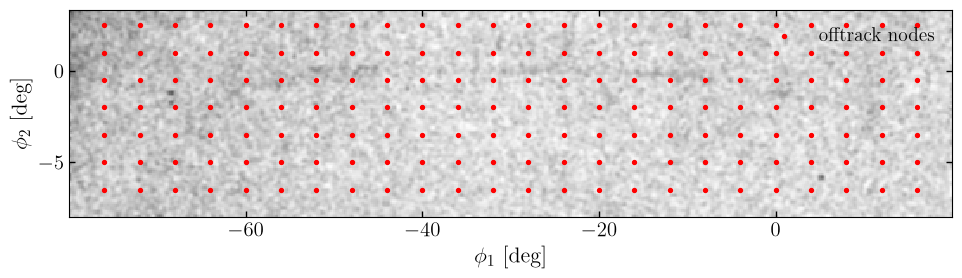

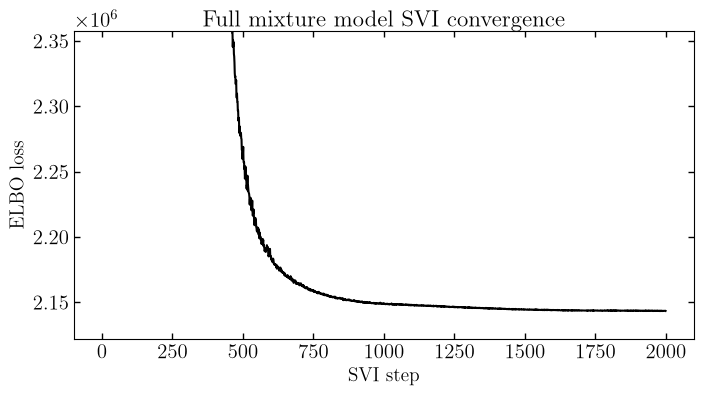

In [37]:
fig, ax = plt.subplots(1, 1, figsize=(10, 3))
plot_data_projections(
    data=run_data, grids=plot_grids, axes=ax,
    coord_names=[("phi1", "phi2")],
    pcolormesh_kwargs=dict(rasterized=True, cmap="gray_r", alpha=0.7),
)
ax.scatter(
    offtrack_phi12_locs[:, 0], offtrack_phi12_locs[:, 1],
    s=8, c="red", label="offtrack nodes",
)
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(full_svi_results.losses)
plt.ylim(0.99 * full_svi_results.losses[-1], 1.1 * full_svi_results.losses[-1])
plt.xlabel("SVI step")
plt.ylabel("ELBO loss")
plt.title("Full mixture model SVI convergence")
plt.show()

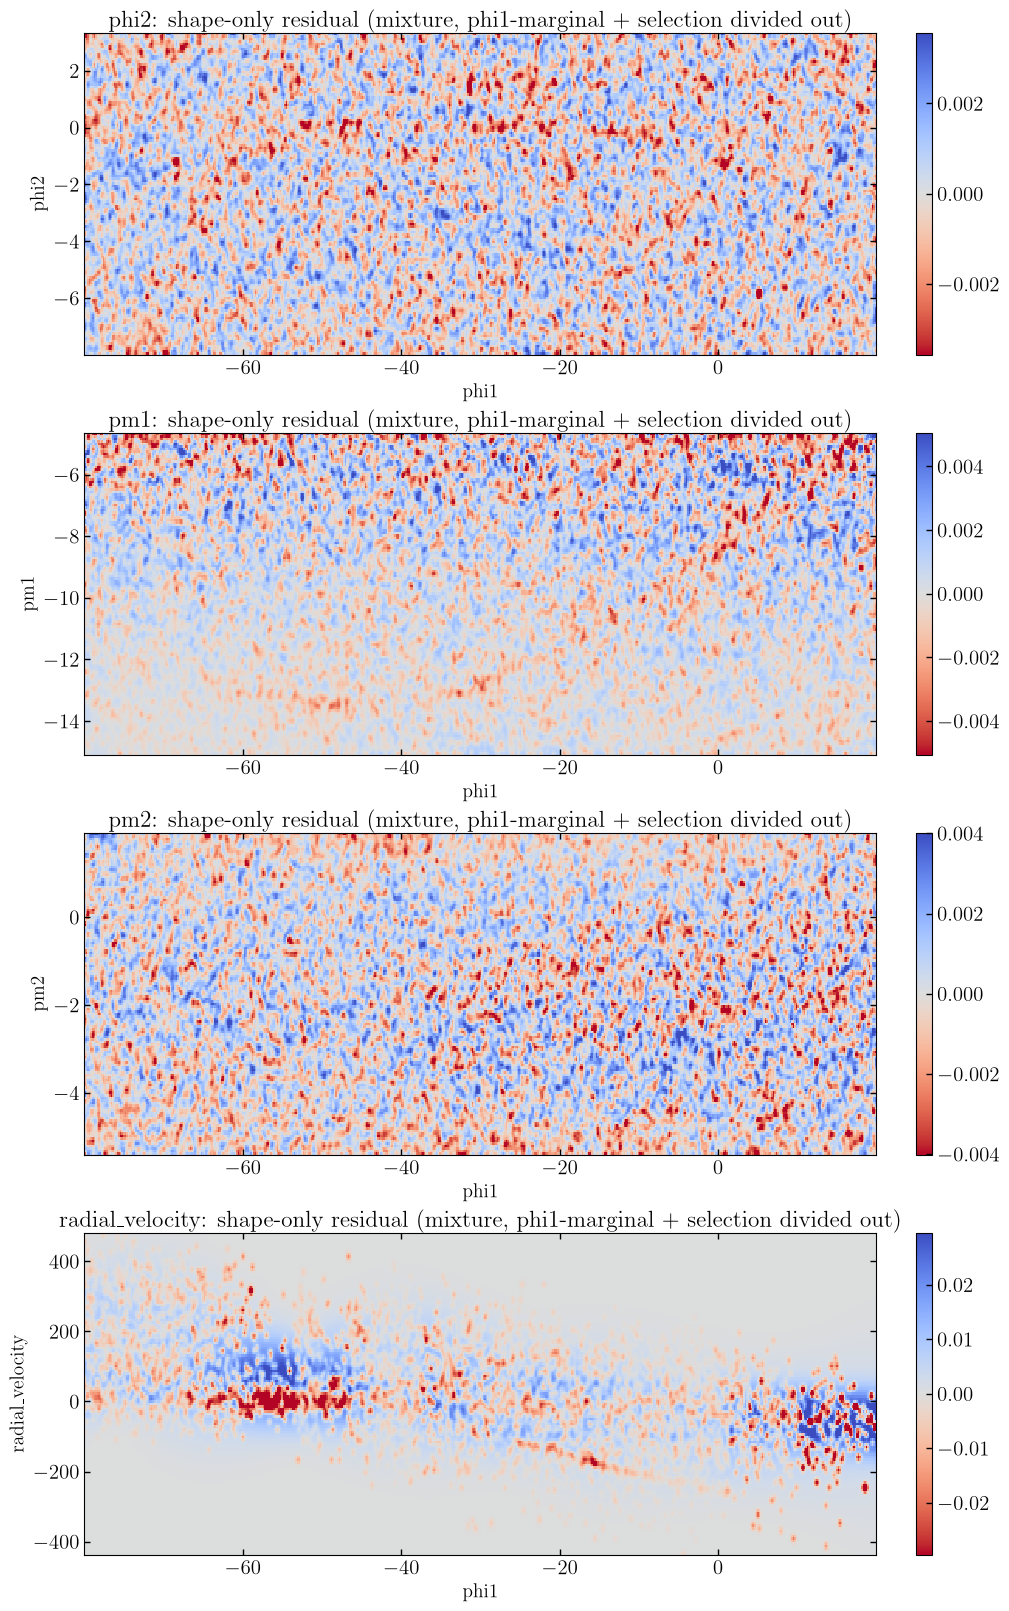

In [ ]:
fig, axes = plt.subplots(4, 1, figsize=(10, 16), constrained_layout=True)
for ax, coord in zip(axes, ["phi2", "pm1", "pm2", "radial_velocity"]):
    plot_shape_only_residual_mixture(
        coord, mm, bkg_data, full_params, plot_grids, ax=ax,
    )
plt.show()


### Full-mixture stream CMD diagnostic (membership-colored)

Same `plot_stream_cmd_fit` panels as in Stage 2, but now using the
Stage 4 full-mixture fit: `compute_membership_probs` turns the fitted
`mm` + `full_params` into per-star membership probabilities (a proper
softmax-normalized mixture responsibility, using the existing
`run_full_gd1_model.make_lp_dict` machinery, which already supports the
`IsochroneCMD` term for free). The CMD scatter is colored by
`p(stream)`, and the "likely members vs. model samples" panel is
restricted to stars with `p(stream) > 0.5`.


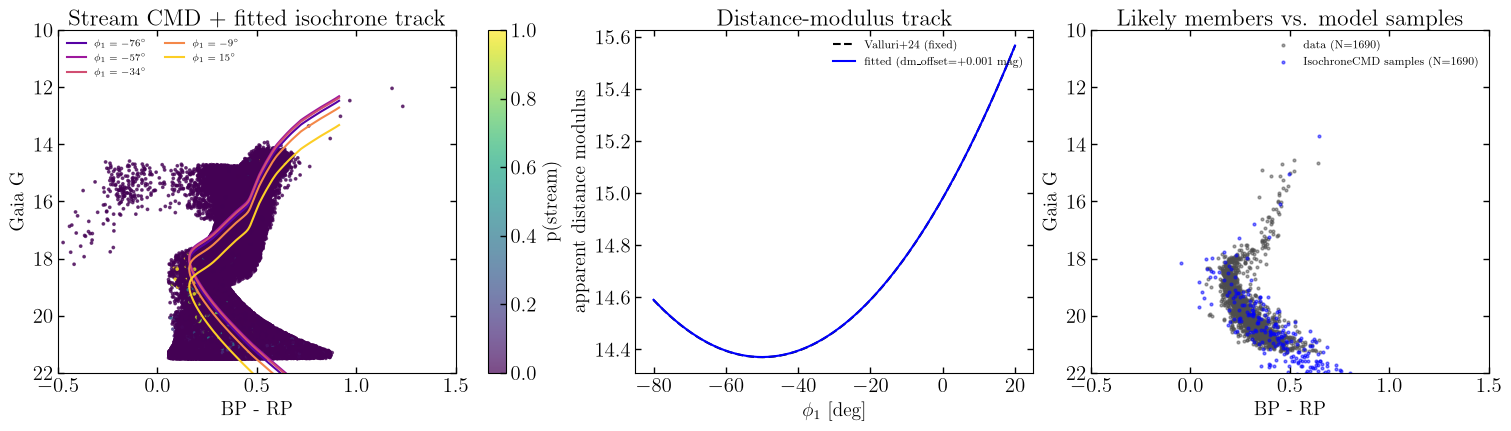

N(p(stream) > 0.5) = 1690 / 192495


In [38]:
from plot_stream_cmd import compute_membership_probs, plot_stream_cmd_fit

if init_stream.CMD_COORD in stream_model_mm.coord_distributions:
    membership = compute_membership_probs(mm, run_data, run_data_err, full_params)
    plot_stream_cmd_fit(
        stream_model_mm, full_params["stream"], run_data,
        membership_probs=membership["stream"],
    )
    plt.show()

    print(f"N(p(stream) > 0.5) = {int((membership['stream'] > 0.5).sum())} / {len(run_data['phi1'])}")
else:
    membership = compute_membership_probs(mm, run_data, run_data_err, full_params)
    print("stream_model_mm has no CMD term (built without stream_isochrone=... above) -- skipping CMD diagnostic.")
    print(f"N(p(stream) > 0.5) = {int((membership['stream'] > 0.5).sum())} / {len(run_data['phi1'])}")


N(p(stream) > 0.50) = 1690 / 192495 (0.0088 of run_data)
Compare to fitted global mixture weight: 0.0070


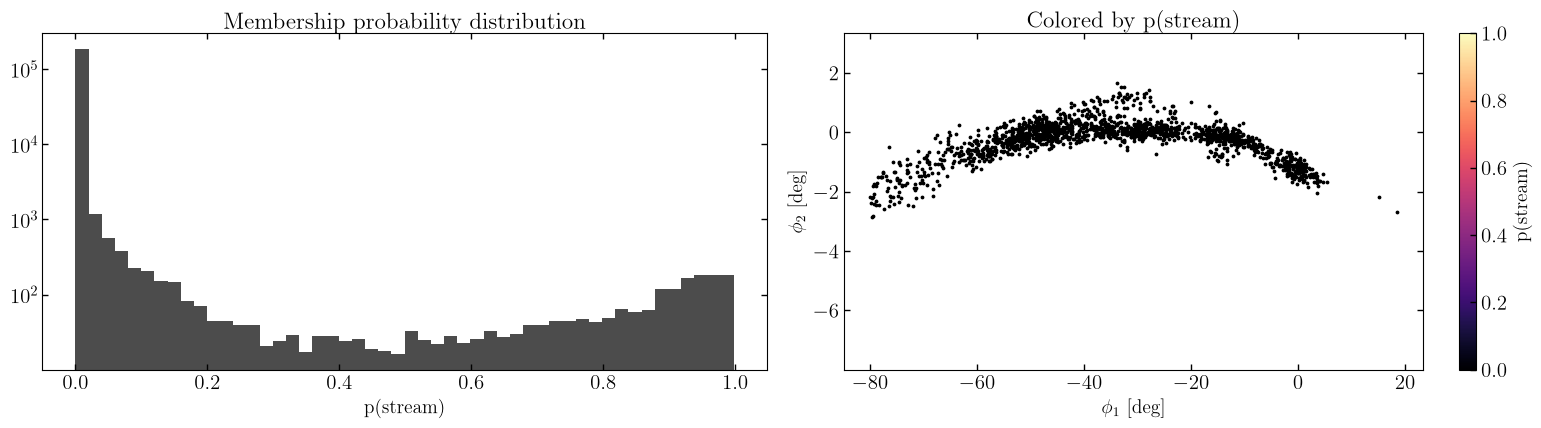

In [39]:
# --- Per-star Stage 4 membership probabilities ---
from plot_stream_cmd import compute_membership_probs

stage4_membership = compute_membership_probs(mm, run_data, run_data_err, full_params)

cutoff = 0.5
likely_members = (stage4_membership["stream"] > cutoff) | (stage4_membership["offtrack"] > cutoff)
n_likely = int(likely_members.sum())
print(f"N(p(stream) > {cutoff:.2f}) = {n_likely} / {len(run_data['phi1'])} "
      f"({n_likely / len(run_data['phi1']):.4f} of run_data)")
print(f"Compare to fitted global mixture weight: {float(full_params['mixture-probs'][1]):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

axes[0].hist(stage4_membership["stream"], bins=50, alpha=0.7)
axes[0].set_yscale("log")
axes[0].set_xlabel("p(stream)")
axes[0].set_title("Membership probability distribution")

sc = axes[1].scatter(
    run_data["phi1"][likely_members], run_data["phi2"][likely_members],# c=stage4_membership["stream"],
    s=3, #cmap=CMAP, vmin=0, vmax=0.0001, rasterized=True,
)
axes[1].set_xlabel(r"$\phi_1$ [deg]")
axes[1].set_ylabel(r"$\phi_2$ [deg]")
axes[1].set_title("Colored by p(stream)")
axes[1].set_ylim(coord_bounds["phi2"])
plt.colorbar(sc, ax=axes[1], label="p(stream)")
plt.tight_layout()
plt.show()

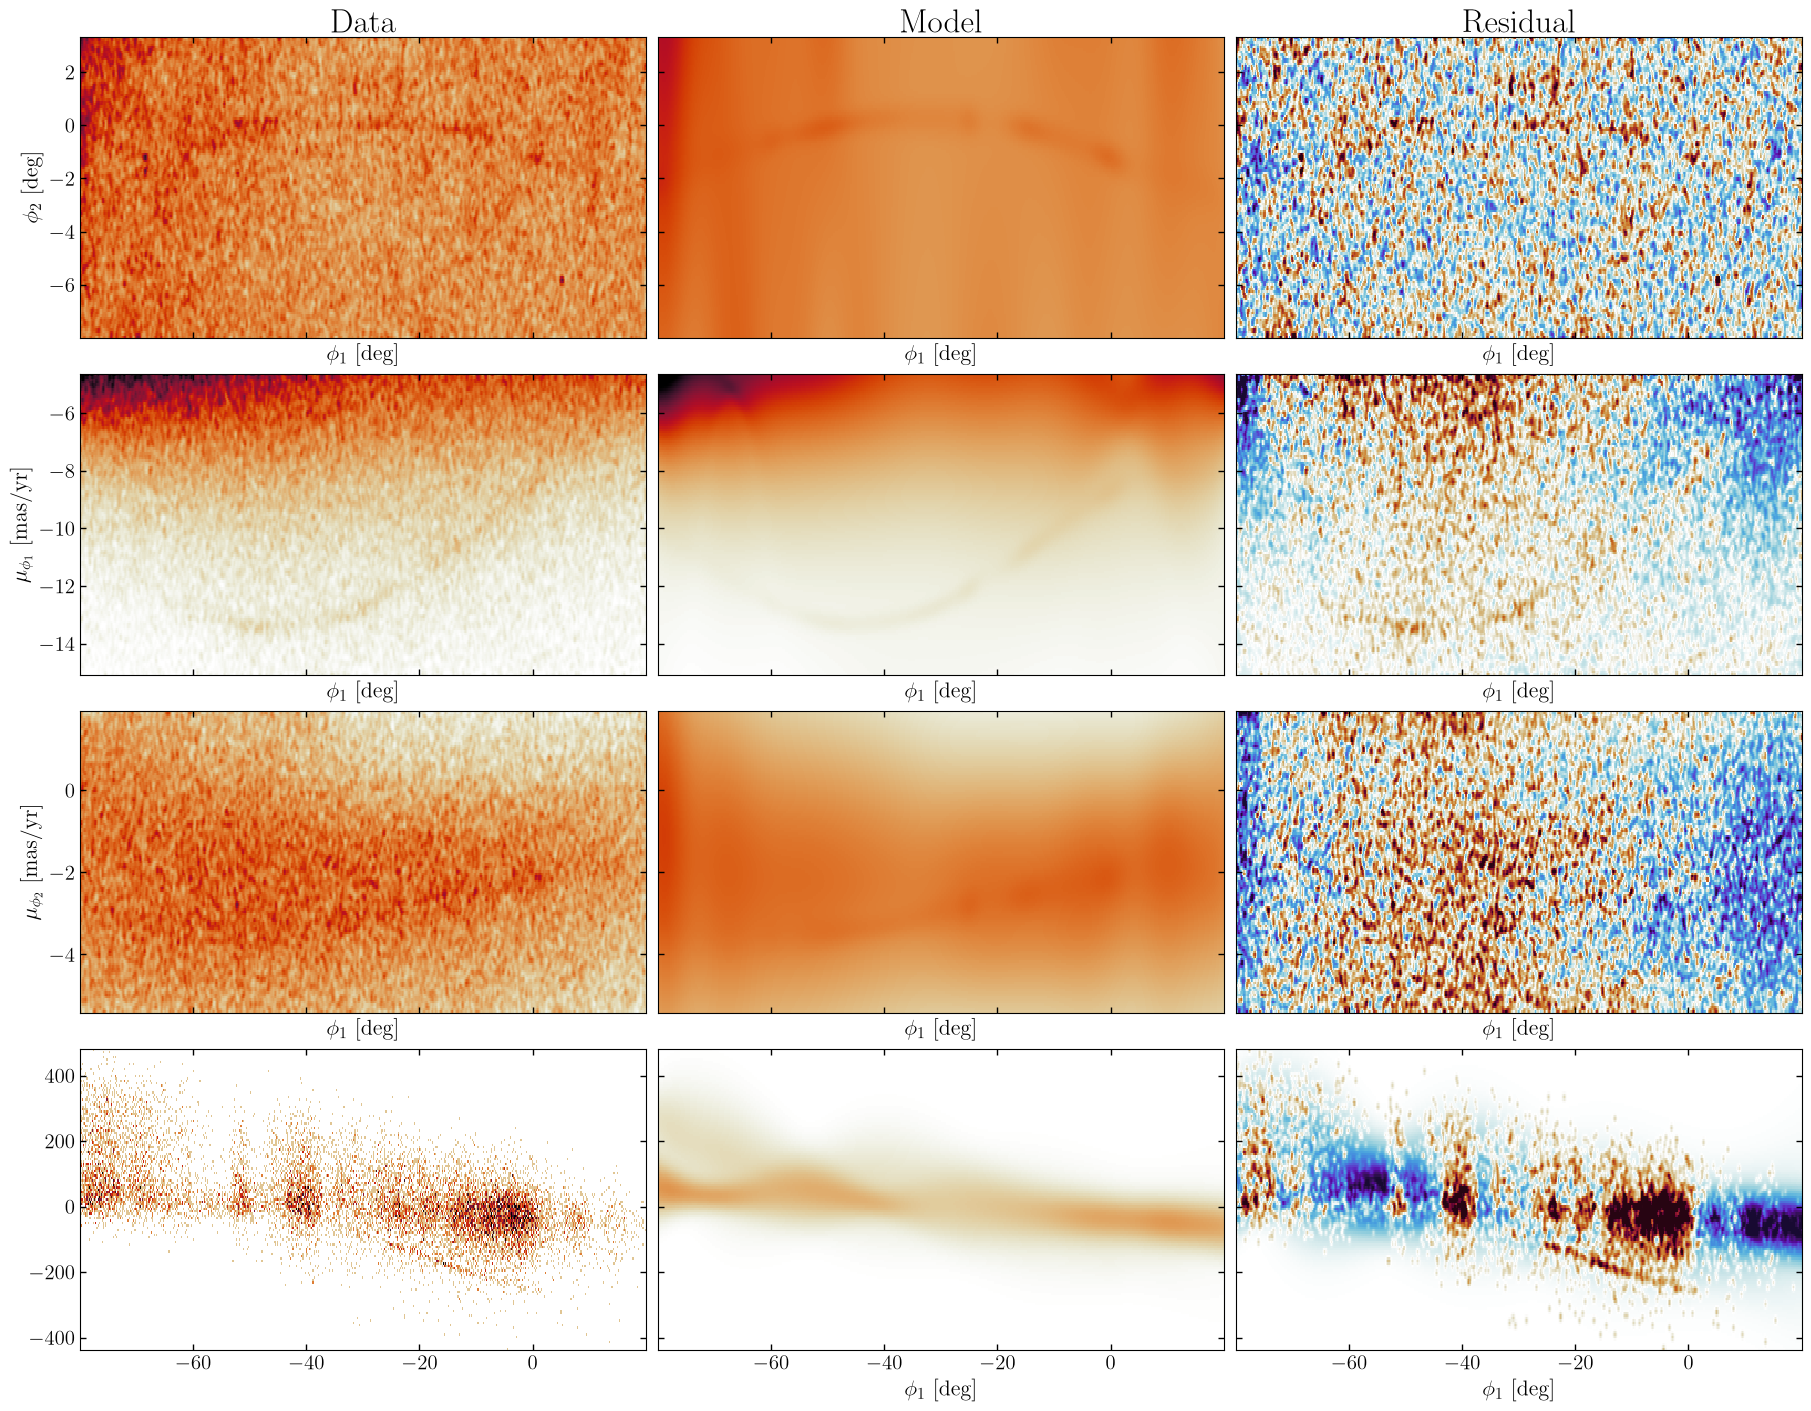

In [40]:
run_x_data = {
    "pm1": init_stream._coord_x(run_data, "pm1"),
    "pm2": init_stream._coord_x(run_data, "pm2"),
    "radial_velocity": init_stream._coord_x(run_data, "radial_velocity"),
}
run_ndata = {
    "phi2": len(run_data["phi1"]),
    "pm1": len(run_data["pm1"]),
    "pm2": len(run_data["pm2"]),
    "radial_velocity": len(run_data["radial_velocity"]),
}

# Data-driven vmax per row (99.5th pctile of the 2D data histogram on the
# same bins as plot_grids), since run_data's total counts/raggedness differ
# per coordinate -- avoids hardcoding a magic constant like the bkg/stream
# cells did for their own, differently-sized data.
def _row_vmax(x, y, xgrid, ygrid, pct=99.5):
    H, *_ = np.histogram2d(x, y, bins=[xgrid, ygrid])
    return np.percentile(H[H > 0], pct) if np.any(H > 0) else 1.0

row_vmax = {
    "phi2": _row_vmax(run_data["phi1"], run_data["phi2"], plot_grids["phi1"], plot_grids["phi2"]),
    "pm1": _row_vmax(run_x_data["pm1"], run_data["pm1"], plot_grids["phi1"], plot_grids["pm1"]),
    "pm2": _row_vmax(run_x_data["pm2"], run_data["pm2"], plot_grids["phi1"], plot_grids["pm2"]),
    "radial_velocity": _row_vmax(
        run_x_data["radial_velocity"], run_data["radial_velocity"],
        plot_grids["phi1"], plot_grids["radial_velocity"],
    ),
}

fig, axes = plt.subplots(
    4, 3, figsize=(18, 3.5 * 4), sharex=True, sharey="row", constrained_layout=True,
)
axes = np.atleast_2d(axes)

# --- Data column ---
plot_data_projections(
    data=run_data, grids=plot_grids, axes=axes[0, 0], coord_names=[("phi1", "phi2")],
    pcolormesh_kwargs=dict(rasterized=True, vmax=row_vmax["phi2"], vmin=0, cmap=CMAP),
)
plot_data_projections(
    data=run_data, grids=plot_grids, axes=axes[1, 0], coord_names=[("phi1", "pm1")],
    pcolormesh_kwargs=dict(rasterized=True, vmax=row_vmax["pm1"], vmin=0, cmap=CMAP),
    x_data=run_x_data,
)
plot_data_projections(
    data=run_data, grids=plot_grids, axes=axes[2, 0], coord_names=[("phi1", "pm2")],
    pcolormesh_kwargs=dict(rasterized=True, vmax=row_vmax["pm2"], vmin=0, cmap=CMAP),
    x_data=run_x_data,
)
axes[3, 0].hist2d(
    run_x_data["radial_velocity"], run_data["radial_velocity"],
    bins=[plot_grids["phi1"], plot_grids["radial_velocity"]],
    cmap=CMAP, vmax=row_vmax["radial_velocity"], vmin=0,
)

# --- Model column (mm = full bkg + stream + offtrack mixture) ---
for row, coord in enumerate(["phi2", "pm1", "pm2", "radial_velocity"]):
    mm.plot_model_projections(
        ndata=run_ndata[coord], grids=plot_grids, grid_coord_names=[("phi1", coord)],
        pars=full_params, axes=axes[row, 1], label=False,
        pcolormesh_kwargs=dict(rasterized=True, vmax=row_vmax[coord], vmin=0, cmap=CMAP),
    )

# --- Residual column (model expected counts - data counts) ---
for row, coord in enumerate(["phi2", "pm1", "pm2", "radial_velocity"]):
    v = row_vmax[coord] / 5
    mm.plot_residual_projections(
        grids=plot_grids, grid_coord_names=[("phi1", coord)], pars=full_params,
        data=run_data, axes=axes[row, 2], label=False,
        pcolormesh_kwargs=dict(vmin=-v, vmax=v, cmap=RESID_CMAP, rasterized=True),
        x_data=run_x_data,
    )

axes[3, 1].set_ylim(coord_bounds["radial_velocity"])
axes[3, 2].set_ylim(coord_bounds["radial_velocity"])
axes[0, 0].set_title("Data", fontsize=24)
axes[0, 1].set_title("Model", fontsize=24)
axes[0, 2].set_title("Residual", fontsize=24)
plt.show()

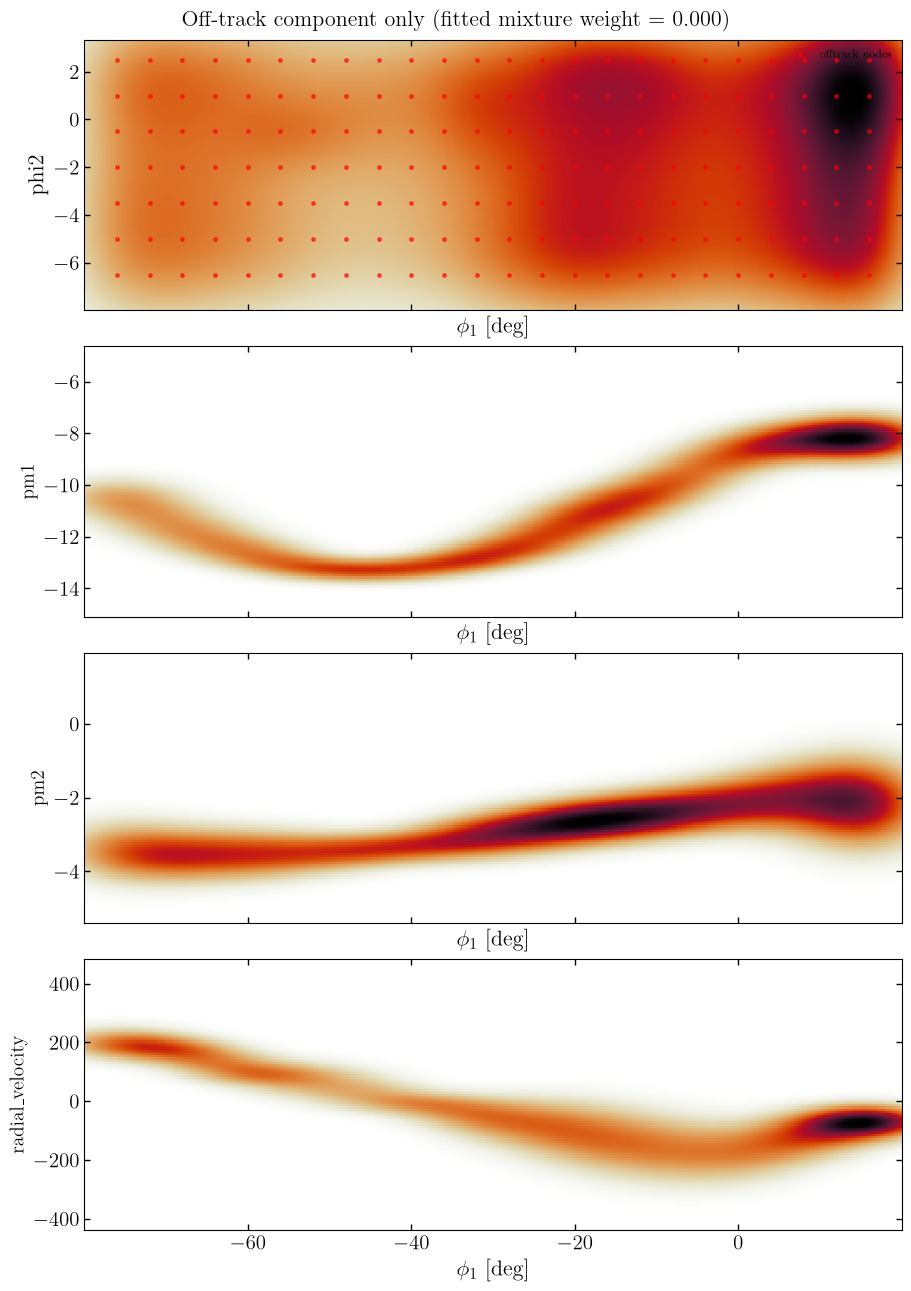

In [43]:
off_prob = float(full_params["mixture-probs"][-1])

fig, axes = plt.subplots(4, 1, figsize=(9, 3.2 * 4), sharex=True, constrained_layout=True)

for row, coord in enumerate(["phi2", "pm1", "pm2", "radial_velocity"]):
    # Scaled by off_prob * N so the color scale reflects the offtrack
    # component's actual expected contribution to run_data's counts within
    # the full mixture -- its own unweighted density always integrates to 1
    # regardless of how small off_prob is, so plotting it unscaled would be
    # misleading next to Block 1's Model column.
    offtrack_model.plot_model_projections(
        ndata=off_prob * run_ndata[coord], grids=plot_grids, grid_coord_names=[("phi1", coord)],
        pars=full_params["offtrack"], axes=axes[row], label=(row == 0),
        pcolormesh_kwargs=dict(rasterized=True, cmap=CMAP, vmin=0),
    )
    axes[row].set_ylabel(coord)

axes[0].scatter(
    offtrack_phi12_locs[:, 0], offtrack_phi12_locs[:, 1],
    s=6, c="red", alpha=0.6, label="offtrack nodes",
)
axes[0].legend(loc="upper right", fontsize=8)
axes[3].set_ylim(coord_bounds["radial_velocity"])
fig.suptitle(f"Off-track component only (fitted mixture weight = {off_prob:.3f})", fontsize=16)
plt.show()

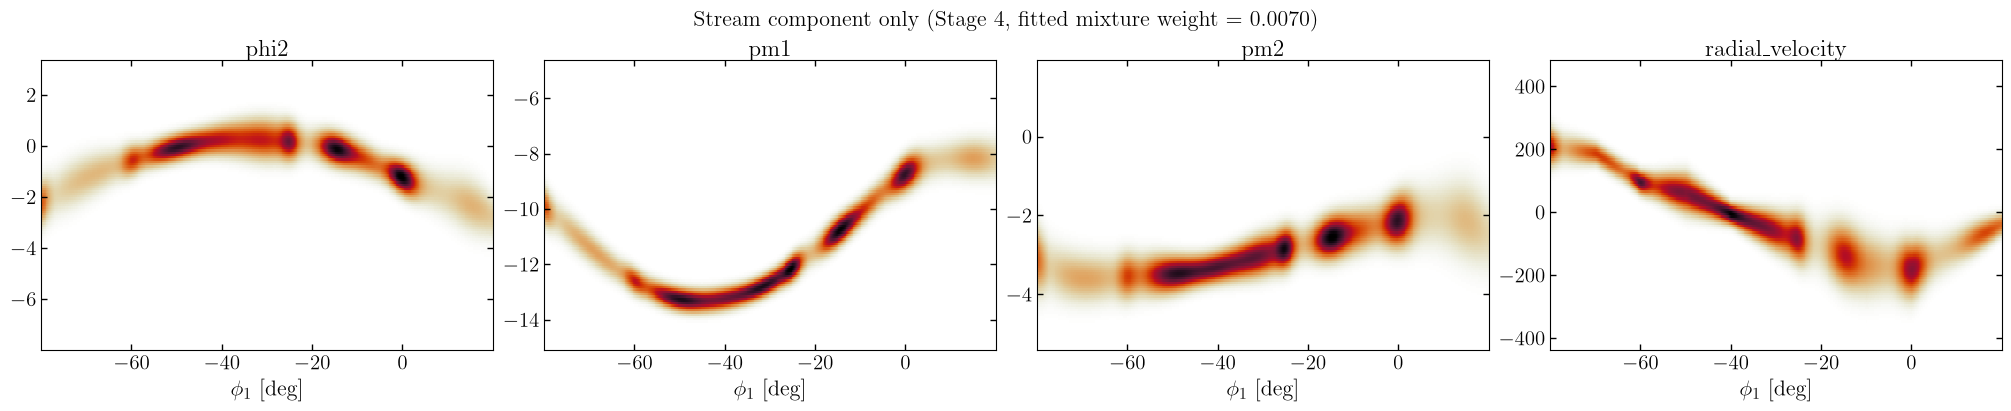

In [44]:
# Isolate just the stream component's model density from the Stage 4 (bkg + stream + offtrack) fit.
# stream_model_mm's own log_prob always integrates to 1 (it's a single
# ModelComponent, not the full mixture), so scale by the *fitted* stream
# mixture weight to see its expected contribution to run_data's total
# counts -- same pattern as the offtrack_model / off_prob cell.

# --- Stage 4 (mm = bkg + stream + offtrack) ---
stream_pars = full_params["stream"]
stream_prob = float(full_params["mixture-probs"][1])   # order is [bkg, stream, offtrack]

fig, axes = plt.subplots(1, 4, figsize=(20, 4), constrained_layout=True)

for ax, coord in zip(axes, ["phi2", "pm1", "pm2", "radial_velocity"]):
    stream_model_mm.plot_model_projections(
        ndata=stream_prob * run_ndata[coord],      # expected-counts scaling
        # ndata=run_ndata[coord],                  # <- swap in for raw shape/density instead
        grids=plot_grids, grid_coord_names=[("phi1", coord)],
        pars=stream_pars, axes=ax, label=False,
        pcolormesh_kwargs=dict(rasterized=True, cmap=CMAP),
    )
    ax.set_title(coord)

axes[-1].set_ylim(coord_bounds["radial_velocity"])
plt.suptitle(f"Stream component only (Stage 4, fitted mixture weight = {stream_prob:.4f})", fontsize=16)
plt.show()

/var/folders/f1/wqzqbly11d9__jf5mjckhwvm0000gq/T/ipykernel_1864/407118701.py:1: UserWarning: Using `field(init=False)` on `equinox.Module` can lead to surprising behaviour
when used around `jax.grad`. In the following example, observe how JAX computes
gradients with respect to the `.len` attribute (which is a PyTree leaf passed
across the `jax.grad` boundary) and that there are no gradients with respect to
`.a` or `.b`:

```
import equinox as eqx
import jax
import jax.numpy as jnp

class Foo(eqx.Module):
    a: jax.Array
    b: jax.Array
    len: jax.Array = eqx.field(init=False)

    def __post_init__(self):
        self.len = jnp.sqrt(self.a**2 + self.b**2)

    def __call__(self, x):
        return self.len * x

@jax.jit
@jax.grad
def call(module, x):
    return module(x)

grads = call(Foo(jnp.array(3.0), jnp.array(4.0)), 5)
# Foo(
#   a=Array(0., dtype=float32, weak_type=True),
#   b=Array(0., dtype=float32, weak_type=True),
#   len=Array(5., dtype=float32, weak_type=True)
# )
```


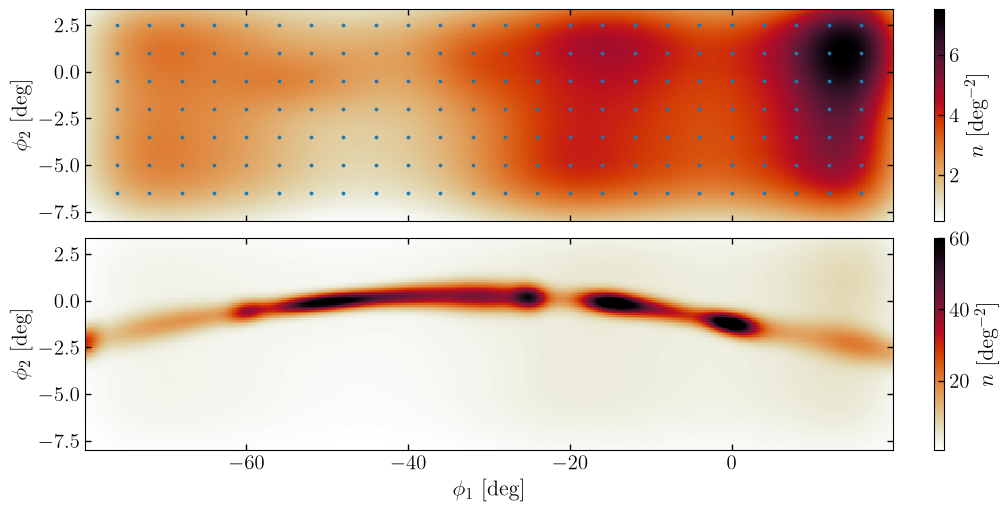

In [49]:
str_off_mm = ComponentMixtureModel(
    dist.Dirichlet(jnp.array([1.0, 1.0])),
    components=[stream_model_mm, offtrack_model],
    # tied_coordinates={"offtrack": {"pm1": "stream", "pm2": "stream"}},
    )

str_off_mm_params = {
    "stream": full_params["stream"],
    "offtrack": full_params["offtrack"],
    "mixture-probs": full_params["mixture-probs"][1:]
}

bin_area = jnp.diff(plot_grids['phi1'])[0] * jnp.diff(plot_grids['phi2'])[0]

fig, [ax1, ax2] = plt.subplots(2,1,figsize=(10,5), sharex=True, constrained_layout=True)
_, _, pcms1 = mm['offtrack'].plot_model_projections(ndata=len(run_data['phi1']), 
                                                    grids=plot_grids, pars=full_params['offtrack'], grid_coord_names=[('phi1', 'phi2')], 
                                                    axes=ax1, pcolormesh_kwargs=dict(rasterized=True, cmap=CMAP))#, 
                                                                                    #  norm=mpl.colors.LogNorm(vmin=1, vmax=30)))
ax1.scatter(mm['offtrack'].coord_parameters[('phi1','phi2')]['locs'][0], 
            mm['offtrack'].coord_parameters[('phi1','phi2')]['locs'][1], color="tab:blue", s=3)
cbar1 = fig.colorbar(pcms1[0], ax=ax1)#, ticks=jnp.array([0, 0.2, .4, .6, .8])*bin_area, pad=0.02,
           # format=mticker.FixedFormatter(['0', '0.2', '0.4', '0.6', '0.8']))

# _, _, pcms2 = str_off_mm.plot_model_projections(ndata=len(run_data_) * jnp.sum(MAP_p_expanded["mixture-probs"][1:]),
#                                                 pars=str_off_mm_packed_params, grids=plot_grids, grid_coord_names=[('phi1', 'phi2')], axes=ax2, label=True,
#                                                 pcolormesh_kwargs=dict(rasterized=True, vmax=0.9, vmin=0, cmap=cmap))
# cbar2 = fig.colorbar(pcms2[0], ax=ax2, ticks=jnp.array([0, 10, 20, 30, 40, 50])*bin_area, pad=0.02,
#            format=mticker.FixedFormatter(['0', '10', '20', '30', '40', '50']), extend='max')

_, _, pcms2 = mm['stream'].plot_model_projections(ndata=len(run_data['phi1']),
                                                pars=full_params['stream'], grids=plot_grids, grid_coord_names=[('phi1', 'phi2')], axes=ax2, label=True,
                                                pcolormesh_kwargs=dict(rasterized=True, cmap=CMAP))
im2 = plt.pcolormesh(plot_grids['phi1'], plot_grids['phi2'], pcms2[0].get_array()+pcms1[0].get_array(), 
                     rasterized=True, cmap=CMAP, vmax=60)
cbar2 = fig.colorbar(im2, ax=ax2)




ax1.set_xlabel("")
cbar1.set_label(label=r'$n$ [deg$^{-2}$]', fontsize=16)
cbar2.set_label(label=r'$n$ [deg$^{-2}$]', fontsize=16)


# plt.savefig('../../paper_figures/offtrack_model.pdf')
# plt.savefig('../../paper_figures/offtrack_model.png')
plt.show()


## Summary

Cached SVI results for each stage are written to `svi_results/` under
`ROOT_DIR`, keyed by knot spacing (so rerunning this notebook with the same
`BKG_KNOT_SPACINGS` / `STREAM_KNOT_SPACINGS` / `OFFTRACK_DX` picks up the
cached fits instead of refitting). Delete the relevant `.pkl` file (or change
the spacings) to force a refit of a given stage.

**CMD terms:** the background (pretrained normalizing flow) and stream
(fixed SSP isochrone, `IsochroneCMD`) both now have a CMD term, and both are
included throughout, including the Stage 3/4 joint mixtures. The offtrack
component reuses the stream's `IsochroneCMD` term directly (see
`make_offtrack_model_component` in `scripts/initialize_stream.py`), since
offtrack stars are physically stream stars that have scattered spatially off
the main track, and `ComponentMixtureModel` requires every mixture component
to share the same coordinates. If `data/stream_isochrone_gaia.json` isn't
found (see the isochrone-loading cell above), all of this gracefully
degrades to no CMD term anywhere in the pipeline, rather than a partial/
mismatched state.

**Next steps / things intentionally out of scope here:**

- `generate_stream_isochrone.py` needs to be run once on a machine with
  normal internet access (to download the MIST grid data), with the
  resulting `data/stream_isochrone_gaia.json` copied back here -- it cannot
  be generated inside this sandbox (see that script's module docstring).
- On your machine (`HAVE_CATS = True`), set `SMOKE_TEST = False` to run the
  full-length production fit (this notebook's `NUM_STEPS` defaults then match
  `scripts/run_full_gd1_model.py`'s CLI defaults).
- For a production CMD flow (rather than the quick/proxy one trained
  automatically above if missing), run
  `python scripts/pretrain_bkg_cmd_flow.py --data data/GD1-region-alldata.fits --out data/bkg_cmd_flow`
  directly, ideally pointed at the real `bkg_data_` selection rather than the
  proxy selection it uses by default (see that script's module docstring).


In [202]:
with open('/Users/Tavangar/Work/gd1-dr3/data/post_cats_data_flow_version.pkl', "rb") as f:
    obj = pickle.load(f)

bkg_tbl = obj['bkg_data'] if isinstance(obj, dict) else obj

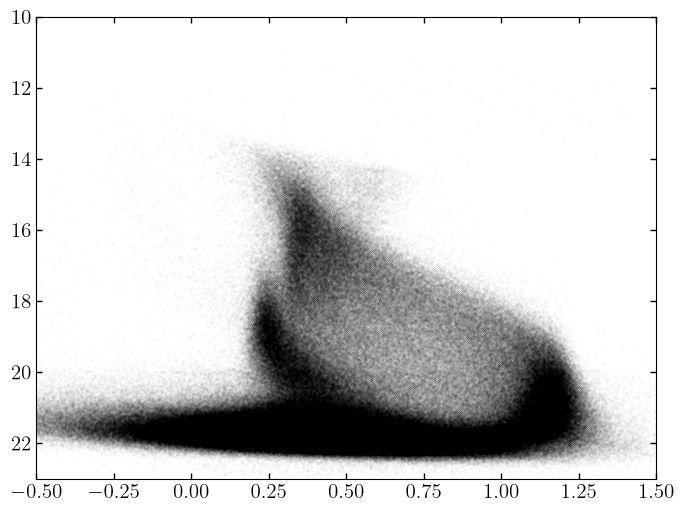

In [207]:
plt.scatter(bkg_tbl['g_0']-bkg_tbl['r_0'], bkg_tbl['g_0'], s=0.001, alpha=0.5)
plt.xlim(-0.5, 1.5)
plt.ylim(10, 23)
plt.gca().invert_yaxis()

plt.show()